# Dự đoán giá bất động sản dựa trên đặc điểm nhà ở
## Hồi quy tuyến tính có chính quy hóa: Ridge (L2), Lasso (L1), Elastic Net

**Dữ liệu:** [tinixai/vietnam-real-estates](https://huggingface.co/datasets/tinixai/vietnam-real-estates), 3.500.744 tin rao bán BĐS Việt Nam (06/2025 – 03/2026).

**Phạm vi:** nhà ở (Nhà riêng, Căn hộ chung cư, Biệt thự/Nhà liền kề) tại **TP. Hồ Chí Minh** và **Hà Nội**. Hai thành phố này chiếm ~70% số tin; loại "Đất" và "Shophouse" bị loại vì không phải nhà ở.

**Nội dung:**
1. Cơ sở toán học của chính quy hóa L1, L2, Elastic Net và vai trò của tham số α
2. Tiền xử lý: giá trị thiếu, ngoại lai, mã hóa biến phân loại, biến đổi log biến mục tiêu
3. Huấn luyện và so sánh Linear Regression, Ridge, Lasso, Elastic Net (chọn α bằng RidgeCV, LassoCV, ElasticNetCV); Random Forest để đối chiếu
4. Đánh giá bằng MAE, RMSE, MAPE; đường đi hệ số (coefficient path) và khả năng lựa chọn đặc trưng của Lasso
5. Demo: lưu mô hình, hàm dự đoán giá cho một căn nhà bất kỳ, đối chiếu với tin đăng thật

---
# Phần 1. Cơ sở toán học

### 1.1. Hồi quy tuyến tính bình phương tối thiểu (OLS)

Cho $n$ mẫu, ma trận đặc trưng $X \in \mathbb{R}^{n \times p}$, vector mục tiêu $y \in \mathbb{R}^n$. Mô hình $\hat y = Xw + b$. OLS tìm $w$ cực tiểu tổng bình phương sai số:

$$\min_w \; \|y - Xw\|_2^2 \quad\Rightarrow\quad \hat w_{OLS} = (X^\top X)^{-1} X^\top y$$

Vấn đề: khi các đặc trưng **đa cộng tuyến** (ví dụ số phòng ngủ và số phòng tắm, hay diện tích và số tầng) hoặc $p$ lớn so với $n$, ma trận $X^\top X$ gần suy biến → hệ số có **phương sai rất lớn**, mô hình dễ **quá khớp (overfitting)**. Chính quy hóa thêm một **hạng phạt** lên độ lớn của $w$ để đánh đổi một ít độ chệch (bias) lấy phương sai (variance) nhỏ hơn.

### 1.2. Ridge – chính quy hóa L2

$$\min_w \; \|y - Xw\|_2^2 + \alpha \|w\|_2^2, \qquad \|w\|_2^2 = \sum_{j=1}^p w_j^2$$

Hàm mục tiêu lồi và khả vi, đặt gradient bằng 0 được nghiệm đóng:

$$\hat w_{Ridge} = (X^\top X + \alpha I)^{-1} X^\top y$$

Việc cộng $\alpha I$ làm ma trận luôn khả nghịch với $\alpha > 0$. Phân tích SVD $X = U D V^\top$ (giá trị kỳ dị $d_j$):

$$X\hat w_{Ridge} = \sum_{j} u_j \,\frac{d_j^2}{d_j^2 + \alpha}\, u_j^\top y$$

Hệ số co $\frac{d_j^2}{d_j^2+\alpha} \in (0,1)$: các hướng có phương sai nhỏ (ứng với $d_j$ nhỏ, chính là các hướng đa cộng tuyến) bị co mạnh nhất. Ridge **co tất cả hệ số về 0 nhưng không bao giờ đưa về đúng 0**, nên không lựa chọn đặc trưng.

### 1.3. Lasso – chính quy hóa L1

$$\min_w \; \frac{1}{2n}\|y - Xw\|_2^2 + \alpha \|w\|_1, \qquad \|w\|_1 = \sum_{j=1}^p |w_j|$$

$|w_j|$ không khả vi tại 0 nên không có nghiệm đóng; giải bằng **coordinate descent** (cách scikit-learn dùng). Xét trường hợp các cột của $X$ trực chuẩn ($X^\top X = nI$), nghiệm tách theo từng tọa độ thành **toán tử ngưỡng mềm (soft-thresholding)**:

$$\hat w_j^{Lasso} = S_\alpha(\hat w_j^{OLS}) = \operatorname{sign}(\hat w_j^{OLS})\,\max\big(|\hat w_j^{OLS}| - \alpha,\; 0\big)$$

So với Ridge trong cùng điều kiện: $\hat w_j^{Ridge} = \hat w_j^{OLS}/(1+\alpha')$, tức chỉ co theo tỉ lệ. Lasso thì **mọi hệ số có $|\hat w_j^{OLS}| \le \alpha$ đều bị đưa về đúng 0**, nên Lasso **tự động lựa chọn đặc trưng** và cho mô hình thưa (sparse).

**Diễn giải hình học:** bài toán tương đương $\min \|y-Xw\|^2$ với ràng buộc $\|w\|_1 \le t$ (Lasso) hoặc $\|w\|_2 \le t$ (Ridge). Miền L1 là hình thoi có **đỉnh nằm trên các trục**; đường đồng mức elip của hàm mất mát thường chạm miền ràng buộc tại đỉnh, nơi một số $w_j = 0$. Miền L2 là hình tròn, không có đỉnh nên tiếp điểm hầu như không nằm trên trục.

**Diễn giải Bayes:** Ridge ⇔ ước lượng MAP với prior Gauss $w_j \sim \mathcal N(0,\tau^2)$; Lasso ⇔ prior Laplace $p(w_j) \propto e^{-|w_j|/b}$, có đỉnh nhọn tại 0.

**Hạn chế của Lasso:** khi có nhóm đặc trưng tương quan cao, Lasso thường chọn ngẫu nhiên một biến và bỏ các biến còn lại; khi $p > n$, nó chọn tối đa $n$ biến.

### 1.4. Elastic Net – kết hợp L1 và L2

$$\min_w \; \frac{1}{2n}\|y - Xw\|_2^2 + \alpha\,\rho\,\|w\|_1 + \frac{\alpha(1-\rho)}{2}\|w\|_2^2, \qquad \rho = \texttt{l1\_ratio} \in [0,1]$$

- $\rho = 1$ → Lasso; $\rho = 0$ → Ridge.
- Phần L1 vẫn cho nghiệm thưa; phần L2 làm hàm mục tiêu **lồi chặt**, tạo **hiệu ứng nhóm (grouping effect)**: các đặc trưng tương quan cao nhận hệ số gần nhau và được giữ hoặc bỏ cùng nhau, ổn định hơn Lasso.

### 1.5. Vai trò của tham số α

α điều khiển **độ phức tạp** của mô hình (độ lớn "hiệu dụng" của không gian giả thuyết):

| α | Hệ quả |
|---|---|
| $\alpha \to 0$ | Hạng phạt biến mất → trở về OLS: bias thấp, variance cao, dễ quá khớp |
| α vừa phải | Co hệ số, giảm variance; Lasso loại bớt đặc trưng yếu |
| $\alpha \to \infty$ | Mọi $w_j \to 0$, mô hình chỉ còn hằng số $b = \bar y$: bias cao, **dưới khớp (underfitting)** |

Với Lasso tồn tại $\alpha_{max} = \frac{1}{n}\|X^\top y\|_\infty$ mà từ đó trở lên mọi hệ số bằng 0. Số bậc tự do hiệu dụng của Ridge là $df(\alpha) = \sum_j \frac{d_j^2}{d_j^2+\alpha}$, giảm dần từ $p$ về 0 khi α tăng. Với Lasso, df xấp xỉ số hệ số khác 0.

Vì α không học được từ tập huấn luyện (luôn chọn α = 0 thì sai số huấn luyện nhỏ nhất), ta chọn α bằng **kiểm định chéo k-fold**: với mỗi α trên một lưới logarit, huấn luyện trên $k-1$ fold, đo MSE trên fold còn lại, rồi chọn α có MSE trung bình nhỏ nhất (`RidgeCV`, `LassoCV`, `ElasticNetCV`).

> **Lưu ý triển khai:**
> (1) Hạng phạt phụ thuộc thang đo của đặc trưng, nên **bắt buộc chuẩn hóa** (StandardScaler) trước khi chính quy hóa.
> (2) Hệ số chặn $b$ không bị phạt.
> (3) Trong scikit-learn, `Ridge` dùng $\|y-Xw\|^2$ còn `Lasso`/`ElasticNet` dùng $\frac{1}{2n}\|y-Xw\|^2$, nên **giá trị α của hai họ không so sánh trực tiếp được**.

---
# Phần 2. Tiền xử lý dữ liệu

In [1]:
import glob
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import (LinearRegression, RidgeCV, LassoCV, ElasticNetCV,
                                  Ridge, Lasso, ElasticNet)
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from scipy.linalg import LinAlgWarning
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
# X^T X gần suy biến khi α nhỏ (đa cộng tuyến, xem mục 1.1). Đây chính là lý do cần chính quy hóa.
warnings.filterwarnings("ignore", category=LinAlgWarning)
# coordinate descent chưa đạt sai số tol ở α rất nhỏ; ảnh hưởng không đáng kể tới kết quả
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TRAIN_SAMPLE = 50_000       # số mẫu huấn luyện (lấy ngẫu nhiên); từ ~50k trở lên sai số gần như không giảm thêm (mục 5.4)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_GLOB = (r"D:\dataset_machine_learning\.cache\huggingface\hub"
             r"\datasets--tinixai--vietnam-real-estates\snapshots\*\shard_*.parquet")


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

### 2.1. Đọc dữ liệu
Lọc ngay khi đọc Parquet (theo tỉnh và loại BĐS) để tiết kiệm bộ nhớ. Bỏ cột `description` (văn bản dài) và `house_depth` (thiếu 98%).

In [2]:
PROVINCES = ["Hồ Chí Minh", "Hà Nội"]
PROPERTY_TYPES = ["Nhà", "Căn hộ chung cư", "Biệt thự/Nhà liền kề"]
COLUMNS = ["name", "property_type_name", "province_name", "district_name", "ward_name",
           "project_name", "price", "area",
           "floor_count", "frontage_width", "road_width", "bedroom_count", "bathroom_count",
           "house_direction", "published_at"]

t0 = time.time()
files = sorted(glob.glob(DATA_GLOB))
raw = pq.read_table(files, columns=COLUMNS,
                    filters=[("province_name", "in", PROVINCES),
                             ("property_type_name", "in", PROPERTY_TYPES)]).to_pandas()
print(f"{len(files)} shard, {raw.shape[0]:,} dòng, {time.time() - t0:.1f}s")
raw.head()

10 shard, 2,131,469 dòng, 0.6s


,name,property_type_name,province_name,district_name,ward_name,project_name,price,area,floor_count,frontage_width,road_width,bedroom_count,bathroom_count,house_direction,published_at
0,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...",Nhà,Hà Nội,Bắc Từ Liêm,Phúc Diễn,NaN,7450000000,37,NaN,NaN,NaN,4,5,NaN,2025-06-01T05:12:56.941000
1,Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...,Nhà,Hồ Chí Minh,8,5,NaN,9100000000,48,4,4,NaN,3,3,NaN,2025-06-06T04:37:25.903000
2,"Cần bán căn hộ CC Thái An, Nguyễn Văn Quá, Q12...",Căn hộ chung cư,Hồ Chí Minh,12,Đông Hưng Thuận,Thái An Apartment,1300000000,44,NaN,NaN,NaN,1,1,NaN,2025-06-17T05:32:15.491000
3,"MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ...",Nhà,Hồ Chí Minh,Tân Phú,Tân Thành,NaN,9000000000,60,NaN,NaN,NaN,2,3,NaN,2025-06-06T04:06:17.378000
4,"Bán nhà đường Cộng Hòa, ngay ga T3, 77m2, 5PN ...",Nhà,Hồ Chí Minh,Tân Bình,13,NaN,7150000000,77,NaN,NaN,NaN,5,3,NaN,2025-06-23T05:26:50.296000


In [3]:
print("Tỉ lệ thiếu (%):")
print((raw.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

Tỉ lệ thiếu (%):
road_width           83.8
house_direction      77.1
project_name         70.7
floor_count          68.5
frontage_width       56.2
bathroom_count       33.5
bedroom_count        28.8
ward_name            14.7
price                 5.6
district_name         3.2
province_name           0
property_type_name      0
name                    0
area                    0
published_at            0


### 2.2. Làm sạch biến mục tiêu `price`
- `price` lưu dạng chuỗi → ép kiểu số.
- `price = 0` là tin "giá thỏa thuận" → loại.
- Giá < 300 triệu thường là tin cho thuê hoặc ghi nhầm giá/m² → loại. Giá > 500 tỷ coi như lỗi nhập liệu.
- Loại tin trùng lặp (cùng tiêu đề, giá, diện tích, quận) do môi giới đăng lại nhiều lần.

In [4]:
df = raw.copy()
del raw                      # giải phóng bộ nhớ
df["price"] = pd.to_numeric(df["price"], errors="coerce")
n0 = len(df)
df = df[df["price"].notna() & (df["price"] > 0)]
print(f"Bỏ giá thiếu/0 (thỏa thuận): {n0 - len(df):,}")

n0 = len(df)
df = df.drop_duplicates(subset=["name", "price", "area", "district_name"])
print(f"Bỏ tin trùng lặp:           {n0 - len(df):,}")

n0 = len(df)
df = df[df["price"].between(3e8, 5e11)]
print(f"Bỏ giá ngoài [0.3; 500] tỷ: {n0 - len(df):,}")
print(f"Còn lại: {len(df):,}")

Bỏ giá thiếu/0 (thỏa thuận): 149,227
Bỏ tin trùng lặp:           477,296
Bỏ giá ngoài [0.3; 500] tỷ: 2,345
Còn lại: 1,502,601


### 2.3. Ngoại lai ở đặc trưng số
Giá trị phi thực tế (diện tích 82 triệu m², 0 phòng ngủ, đường rộng 500 m…) được đặt thành **NaN** rồi xử lý như giá trị thiếu, thay vì xóa cả dòng.
Riêng `area` là đặc trưng quan trọng nhất và hầu như không thiếu, nên dòng có diện tích phi lý bị **loại**.
Với căn hộ, `floor_count` không có ý nghĩa "số tầng của căn nhà" nên đặt NaN.

In [5]:
VALID_RANGE = {"bedroom_count": (1, 20), "bathroom_count": (1, 20), "floor_count": (1, 15),
               "frontage_width": (1, 50), "road_width": (1, 60)}
for col, (lo, hi) in VALID_RANGE.items():
    bad = ~df[col].between(lo, hi) & df[col].notna()
    print(f"{col:15s}: {bad.sum():>7,} giá trị ngoài [{lo}, {hi}] → NaN")
    df.loc[bad, col] = np.nan
df.loc[df["property_type_name"] == "Căn hộ chung cư", "floor_count"] = np.nan

n0 = len(df)
df = df[df["area"].between(15, 1000)]
print(f"Bỏ diện tích ngoài [15, 1000] m²: {n0 - len(df):,}")

bedroom_count  :   5,124 giá trị ngoài [1, 20] → NaN
bathroom_count :   4,277 giá trị ngoài [1, 20] → NaN
floor_count    :     216 giá trị ngoài [1, 15] → NaN
frontage_width :     693 giá trị ngoài [1, 50] → NaN
road_width     :     474 giá trị ngoài [1, 60] → NaN
Bỏ diện tích ngoài [15, 1000] m²: 5,729


### 2.4. Khai thác thêm đặc trưng từ tiêu đề tin đăng
Tiêu đề chứa nhiều thông tin mà các cột có cấu trúc bị thiếu:
- **Số tầng:** "4 tầng", "1 trệt 2 lầu" → bổ sung `floor_count` khi bị thiếu (chỉ cho Nhà/Biệt thự).
- **Cờ từ khóa** (0/1): mặt tiền, hẻm xe hơi/ô tô, lô góc, thang máy, kinh doanh, sổ hồng/sổ đỏ, nhà mới, nội thất. Đây là ứng viên tốt để kiểm tra khả năng **lựa chọn đặc trưng** của Lasso.

In [ ]:
name = df["name"].fillna("").str.lower()

floors_from_title = pd.to_numeric(name.str.extract(r"(\d{1,2})\s*tầng", expand=False), errors="coerce")
lau = pd.to_numeric(name.str.extract(r"(\d{1,2})\s*lầu", expand=False), errors="coerce")
floors_from_title = floors_from_title.fillna(lau + 1)          # "1 trệt 2 lầu" = 3 tầng
floors_from_title = floors_from_title.where(floors_from_title.between(1, 15))
is_house = df["property_type_name"] != "Căn hộ chung cư"
fill = df["floor_count"].isna() & is_house & floors_from_title.notna()
df.loc[fill, "floor_count"] = floors_from_title[fill]
print(f"Bổ sung floor_count từ tiêu đề: {fill.sum():,} dòng")

KEYWORDS = {
    "kw_mat_tien":   r"mặt tiền|\bmt\b|mặt phố|mặt đường",
    "kw_oto":        r"ô tô|ôtô|oto|xe hơi|\bhxh\b",
    "kw_lo_goc":     r"lô góc|căn góc|\bgóc\b",
    "kw_thang_may":  r"thang máy",
    "kw_kinh_doanh": r"kinh doanh|\bkd\b|mtkd|dòng tiền|cho thuê",
    "kw_so_hong":    r"sổ hồng|sổ đỏ|\bshr\b|\bsđcc\b|chính chủ",
    "kw_nha_moi":    r"nhà mới|mới xây|mới tinh|xây mới",
    "kw_noi_that":   r"nội thất|full nt",
}
for col, pattern in KEYWORDS.items():
    df[col] = name.str.contains(pattern, regex=True).astype(np.int8)
df[list(KEYWORDS)].mean().mul(100).round(1).rename("% tin có từ khóa").to_frame().T

Bổ sung floor_count từ tiêu đề: 307,462 dòng


,kw_mat_tien,kw_oto,kw_lo_goc,kw_thang_may,kw_kinh_doanh,kw_so_hong,kw_nha_moi,kw_noi_that
% tin có từ khóa,20.6,23.6,8.8,6.9,12.3,12,5.3,10.3


### 2.5. Chuẩn hóa biến phân loại và tạo biến thời gian
- `house_direction`: gộp cách viết "Đông - Nam" và "Đông Nam"; giá trị thiếu (69%) hoặc nhiều hướng → nhóm riêng "Không rõ".
- `district`: ghép tỉnh + quận (vì "7" chỉ là Quận 7 của TP.HCM), thiếu → "Không rõ". Tương tự `ward` = quận + phường.
- `project`: tên dự án (chủ yếu với căn hộ), thiếu → "Không thuộc dự án".
- `district_type`: **biến tương tác quận × loại hình**. Mô hình tuyến tính cộng tính không tự học được việc "chênh lệch giá giữa nhà riêng và căn hộ khác nhau theo từng quận", nên ta tạo tương tác thủ công.
- `month_idx`: số tháng kể từ 06/2025, biểu diễn xu hướng giá theo thời gian.

In [7]:
VALID_DIRECTIONS = {"Đông", "Tây", "Nam", "Bắc", "Đông Nam", "Đông Bắc", "Tây Nam", "Tây Bắc"}
direction = df["house_direction"].str.replace(" - ", " ", regex=False)
df["direction"] = direction.where(direction.isin(VALID_DIRECTIONS), "Không rõ")

df["district"] = df["province_name"] + " | " + df["district_name"].fillna("Không rõ")
df["ward"] = df["district"] + " | " + df["ward_name"].fillna("Không rõ")
df["project"] = df["project_name"].fillna("Không thuộc dự án")
df["district_type"] = df["district"] + " × " + df["property_type_name"]
df["name"] = df["name"].fillna("")
df["published_at"] = pd.to_datetime(df["published_at"], format="ISO8601")
df["month_idx"] = (df["published_at"].dt.year - 2025) * 12 + df["published_at"].dt.month - 6

# Biến mục tiêu và biến diện tích ở thang log
df["log_price"] = np.log(df["price"])
df["log_area"] = np.log(df["area"])
df["price_per_m2"] = df["price"] / df["area"] / 1e6        # triệu/m², chỉ dùng cho EDA và lọc ngoại lai
print(df.shape)

(1496872, 32)


### 2.6. Biến đổi log biến mục tiêu
Giá nhà **lệch phải rất mạnh** (vài tin hàng trăm tỷ kéo đuôi phân phối). Hồi quy tuyến tính giả định sai số có phân phối đối xứng, phương sai đồng nhất, nên ta mô hình hóa $\log(\text{giá})$:
- Phân phối gần chuẩn hơn, giảm ảnh hưởng của tin giá cực lớn.
- Hệ số có nghĩa **tương đối**: tăng 1 đơn vị đặc trưng (đã chuẩn hóa) thì giá nhân thêm $e^{w_j}$, tức thay đổi ≈ $100\,w_j\%$.
- Với `log_area`, hệ số chính là **độ co giãn** của giá theo diện tích.

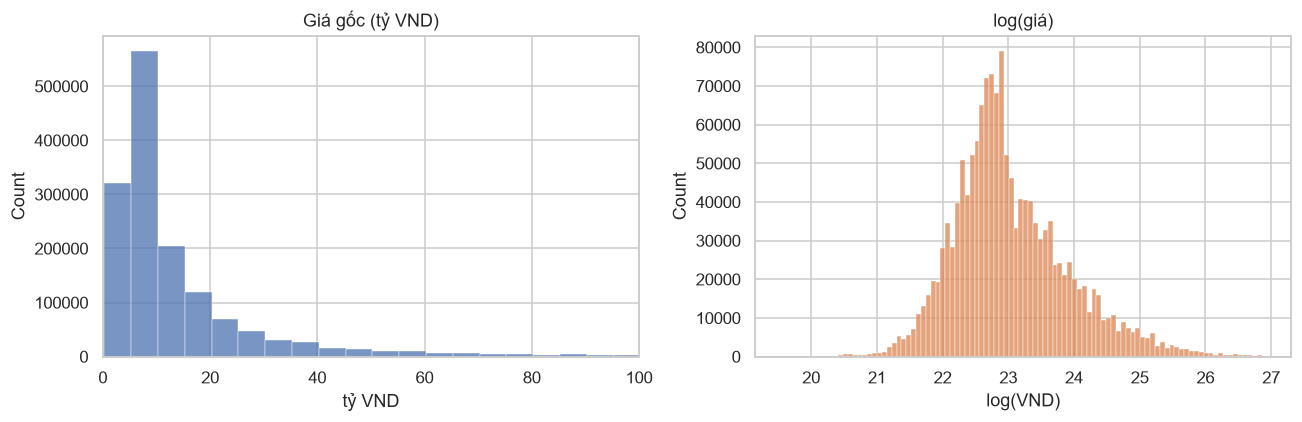

Skewness giá gốc: 6.84 | log(giá): 0.75


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"] / 1e9, bins=100, ax=axes[0])
axes[0].set(title="Giá gốc (tỷ VND)", xlabel="tỷ VND", xlim=(0, 100))
sns.histplot(df["log_price"], bins=100, ax=axes[1], color="C1")
axes[1].set(title="log(giá)", xlabel="log(VND)")
savefig("01_phan_phoi_gia")
print(f"Skewness giá gốc: {df['price'].skew():.2f} | log(giá): {df['log_price'].skew():.2f}")

### 2.7. Chia train/test theo thời gian
Mô phỏng tình huống thực tế: **học trên dữ liệu quá khứ, dự đoán tin mới**.
- Train: 06/2025 – 01/2026
- Test: 02/2026 – 03/2026

Ngưỡng lọc ngoại lai theo **giá/m²** được tính **chỉ trên tập train** (phân vị 1% và 99% theo từng cặp tỉnh × loại hình) rồi áp dụng cho cả hai tập, để tránh rò rỉ thông tin từ tập test.

In [9]:
SPLIT_DATE = pd.Timestamp("2026-02-01")
train_df = df[df["published_at"] < SPLIT_DATE]
test_df = df[df["published_at"] >= SPLIT_DATE]

bounds = (train_df.groupby(["province_name", "property_type_name"])["price_per_m2"]
          .quantile([0.01, 0.99]).unstack())
bounds.columns = ["ppm2_lo", "ppm2_hi"]
display_bounds = bounds.round(1)
print("Ngưỡng giá/m² hợp lệ (triệu/m²):")
print(display_bounds.to_string())


def drop_ppm2_outliers(d):
    d = d.join(bounds, on=["province_name", "property_type_name"])
    keep = d["price_per_m2"].between(d["ppm2_lo"], d["ppm2_hi"])
    return d[keep].drop(columns=["ppm2_lo", "ppm2_hi"])


n_tr, n_te = len(train_df), len(test_df)
train_df = drop_ppm2_outliers(train_df)
test_df = drop_ppm2_outliers(test_df)
print(f"\nTrain: {n_tr:,} → {len(train_df):,} | Test: {n_te:,} → {len(test_df):,}")

Ngưỡng giá/m² hợp lệ (triệu/m²):
                                    ppm2_lo  ppm2_hi
province_name property_type_name                    
Hà Nội        Biệt thự/Nhà liền kề       60    670.5
              Căn hộ chung cư          38.2    184.1
              Nhà                      68.7    842.9
Hồ Chí Minh   Biệt thự/Nhà liền kề     40.1    724.6
              Căn hộ chung cư          23.5      350
              Nhà                      27.2    642.9

Train: 1,271,505 → 1,246,141 | Test: 225,367 → 220,681


### 2.8. Khám phá dữ liệu (EDA) trên tập train

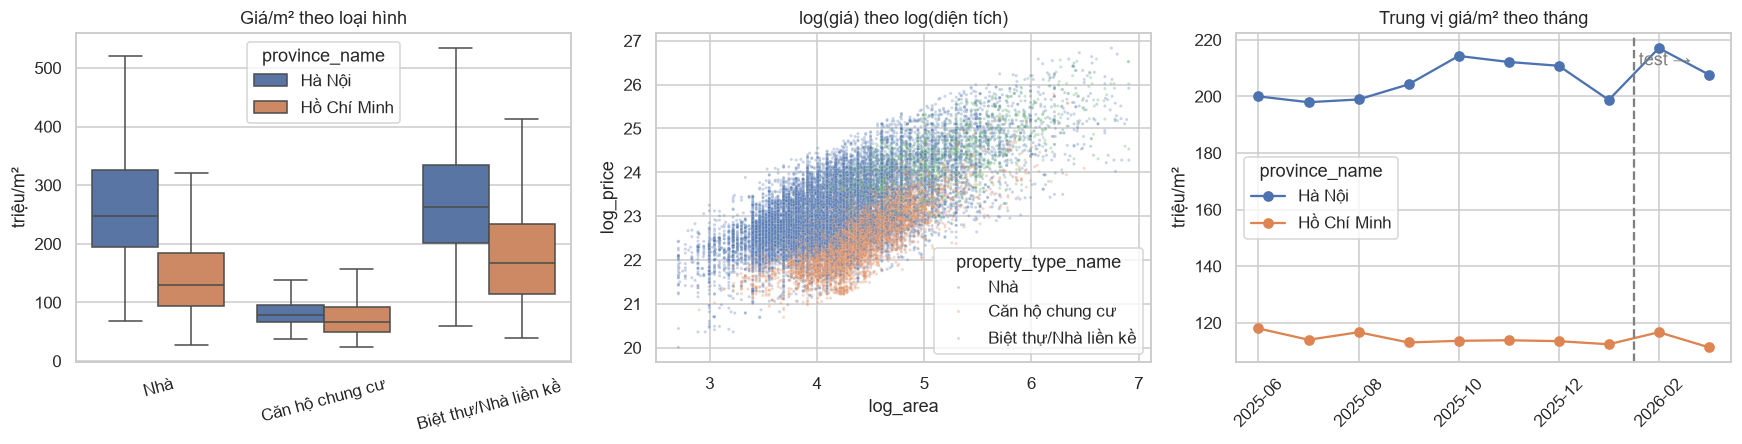

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.boxplot(data=train_df, x="property_type_name", y="price_per_m2", hue="province_name",
            showfliers=False, ax=axes[0])
axes[0].set(title="Giá/m² theo loại hình", xlabel="", ylabel="triệu/m²")
axes[0].tick_params(axis="x", rotation=15)

s = train_df.sample(30_000, random_state=RANDOM_STATE)
sns.scatterplot(data=s, x="log_area", y="log_price", hue="property_type_name", s=4, alpha=.3, ax=axes[1])
axes[1].set(title="log(giá) theo log(diện tích)")

monthly = df.groupby([df["published_at"].dt.to_period("M"), "province_name"])["price_per_m2"].median().unstack()
monthly.index = monthly.index.astype(str)
monthly.plot(marker="o", ax=axes[2])
axes[2].axvline(7.5, ls="--", c="gray")
axes[2].text(7.6, axes[2].get_ylim()[1] * .97, "test →", va="top", color="gray")
axes[2].set(title="Trung vị giá/m² theo tháng", xlabel="", ylabel="triệu/m²")
axes[2].tick_params(axis="x", rotation=45)
savefig("02_eda")

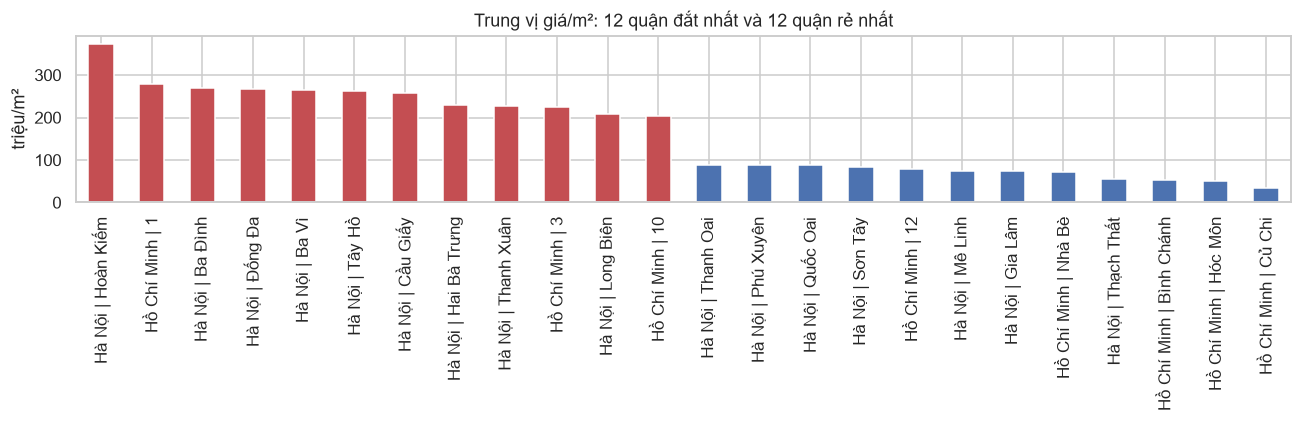

In [11]:
top = (train_df.groupby("district")["price_per_m2"].median().sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(12, 4))
pd.concat([top.head(12), top.tail(12)]).plot.bar(ax=ax, color=["C3"] * 12 + ["C0"] * 12)
ax.set(title="Trung vị giá/m²: 12 quận đắt nhất và 12 quận rẻ nhất", ylabel="triệu/m²", xlabel="")
savefig("03_quan")

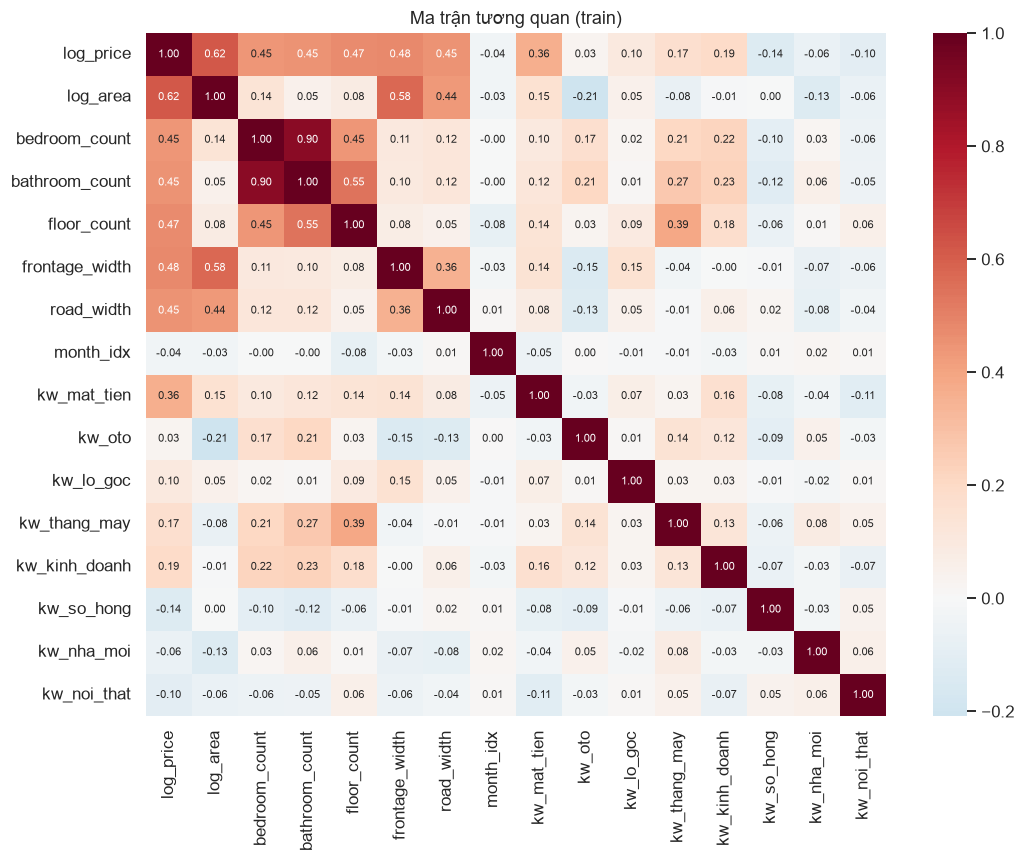

In [12]:
num_check = ["log_price", "log_area", "bedroom_count", "bathroom_count", "floor_count",
             "frontage_width", "road_width", "month_idx"] + list(KEYWORDS)
corr = train_df[num_check].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Ma trận tương quan (train)")
savefig("04_tuong_quan")

### 2.9. Pipeline tiền xử lý
| Nhóm | Đặc trưng | Xử lý |
|---|---|---|
| Số | `log_area`, `bedroom_count`, `bathroom_count`, `floor_count`, `frontage_width`, `road_width`, `month_idx` | Điền **trung vị** + thêm **biến chỉ báo thiếu** (`missingindicator_*`) → StandardScaler |
| Nhị phân | 8 cờ từ khóa | StandardScaler |
| Phân loại | loại hình, tỉnh, quận, hướng, **phường**, **dự án**, **quận × loại hình** | **One-hot** (bỏ cột đầu làm mốc; nhóm có < 70 tin gộp vào "infrequent") → chia độ lệch chuẩn |
| Văn bản | tiêu đề tin đăng | **Bag-of-words nhị phân** (từ đơn + cụm 2 từ, xuất hiện ≥ 100 tin, tối đa 1000 từ) → chia độ lệch chuẩn |

- **Biến chỉ báo thiếu:** việc **thiếu thông tin cũng mang tín hiệu**, ví dụ tin không ghi số phòng thường là nhà nhỏ trong hẻm.
- **Chống rò rỉ giá từ tiêu đề:** tiêu đề thường ghi giá ("giá 7,4 tỷ"), nên ta **bỏ mọi con số** và các từ chỉ đơn vị giá (tỷ, triệu, giá…), chỉ giữ từ mô tả.
- Kết quả là **hơn một nghìn đặc trưng**, nhiều đặc trưng dư thừa hoặc tương quan (quận ↔ phường ↔ quận×loại hình, từ khóa ↔ từ trong tiêu đề). Đây là tình huống chính quy hóa và lựa chọn đặc trưng thật sự có ý nghĩa.
- Cột one-hot và văn bản chỉ được **chia cho độ lệch chuẩn** (`with_mean=False`), không trừ trung bình. Hệ số chặn của mô hình hấp thụ phần trung bình.
- Đầu ra là **ma trận dày float32**. Vì $n \gg p$, Lasso/Elastic Net dùng **ma trận Gram $X^\top X$ ($p \times p$) tính trước**: mỗi vòng coordinate descent chỉ tốn $O(p^2)$, không phụ thuộc $n$. Thử nghiệm cho thấy cách này nhanh hơn 10–30 lần so với coordinate descent trên ma trận thưa.
- Toàn bộ nằm trong `Pipeline`, nên mọi thống kê (trung vị, độ lệch chuẩn, từ điển) chỉ học từ dữ liệu train của mỗi fold.

In [13]:
NUM_COLS = ["log_area", "bedroom_count", "bathroom_count", "floor_count",
            "frontage_width", "road_width", "month_idx"]
BIN_COLS = list(KEYWORDS)
CAT_COLS = ["property_type_name", "province_name", "district", "direction",
            "ward", "project", "district_type"]
TEXT_COL = "name"
FEATURES = NUM_COLS + BIN_COLS + CAT_COLS + [TEXT_COL]

PRICE_WORDS = ["tỷ", "tỉ", "ty", "triệu", "trieu", "tr", "giá", "gia", "chỉ", "hơn", "nhỉnh",
               "còn", "phone_number", "phone", "number", "lh", "liên", "hệ"]


def make_preprocessor():
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", StandardScaler())])
    cat = Pipeline([("onehot", OneHotEncoder(drop="first", handle_unknown="ignore",
                                             min_frequency=70)),
                    ("scale", StandardScaler(with_mean=False))])
    text = Pipeline([("bow", CountVectorizer(binary=True, ngram_range=(1, 2), min_df=100,
                                             max_features=1000, stop_words=PRICE_WORDS,
                                             token_pattern=r"(?u)\b[^\W\d_]{2,}\b")),
                     ("scale", StandardScaler(with_mean=False))])
    columns = ColumnTransformer([("num", num, NUM_COLS),
                                 ("kw", StandardScaler(), BIN_COLS),
                                 ("cat", cat, CAT_COLS),
                                 ("text", text, TEXT_COL)],
                                sparse_threshold=0)            # luôn trả về ma trận dày
    to_f32 = FunctionTransformer(np.asarray, kw_args={"dtype": np.float32},
                                 feature_names_out="one-to-one")
    return Pipeline([("columns", columns), ("float32", to_f32)])


train_fit = (train_df.sample(TRAIN_SAMPLE, random_state=RANDOM_STATE)
             if TRAIN_SAMPLE and len(train_df) > TRAIN_SAMPLE else train_df)
X_train, y_train = train_fit[FEATURES], train_fit["log_price"].to_numpy()
X_test, y_test = test_df[FEATURES], test_df["log_price"].to_numpy()
del df, train_df                 # giải phóng bộ nhớ: từ đây chỉ cần X_train / X_test

pre_tr = make_preprocessor().fit(X_train)
Xs_train = pre_tr.transform(X_train)
feature_names = pre_tr.get_feature_names_out()


def feature_group(f):
    """num__log_area → 'num'; cat__ward_... → 'ward'; text__mặt tiền → 'text'."""
    block, rest = f.split("__", 1)
    if block == "cat":
        # so khớp tên cột dài nhất trước, để "district_type_..." không bị nhận nhầm là "district"
        return next(c for c in sorted(CAT_COLS, key=len, reverse=True) if rest.startswith(c + "_"))
    return block


groups = pd.Series([feature_group(f) for f in feature_names], index=feature_names)
print(f"Train dùng để huấn luyện: {len(X_train):,} | Test: {len(X_test):,}")
print(f"Số đặc trưng sau tiền xử lý: {len(feature_names):,} "
      f"| ma trận {Xs_train.shape}, {Xs_train.nbytes / 1e9:.2f} GB")
groups.value_counts().rename("số đặc trưng").to_frame().T

Train dùng để huấn luyện: 50,000 | Test: 220,681
Số đặc trưng sau tiền xử lý: 1,407 | ma trận (50000, 1407), 0.28 GB


,text,ward,district_type,district,num,project,kw,direction,property_type_name,province_name
số đặc trưng,1000,241,86,38,12,11,8,8,2,1


---
# Phần 3. Huấn luyện và chọn α bằng kiểm định chéo
Cả 4 mô hình tuyến tính dùng **cùng pipeline tiền xử lý** để so sánh công bằng.
- `LinearRegression`: OLS, không chính quy hóa (mốc so sánh)
- `RidgeCV`: α trên lưới $10^{-1} \dots 10^{6}$, **5-fold CV**
- `LassoCV`: α trên lưới $10^{-5} \dots 10^{-1}$, **5-fold CV**
- `ElasticNetCV`: lưới 2 chiều (α × l1_ratio ∈ {0.2, 0.5, 0.8}), **5-fold CV**
- `RandomForestRegressor`: mô hình phi tuyến để đối chiếu

⏱ Phần huấn luyện mất khoảng 5–10 phút tùy máy. Có thể giảm `TRAIN_SAMPLE` để chạy nhanh hơn. `n_jobs=4` (không dùng -1) để giới hạn RAM, vì mỗi tiến trình CV giữ một bản sao dữ liệu fold.

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
RIDGE_ALPHAS = np.logspace(-1, 6, 30)
LASSO_ALPHAS = np.logspace(-5, -1, 25)
L1_RATIOS = [0.2, 0.5, 0.8]

models = {
    "Linear Regression": LinearRegression(),
    "Ridge":       RidgeCV(alphas=RIDGE_ALPHAS, cv=cv),
    "Lasso":       LassoCV(alphas=LASSO_ALPHAS, cv=cv, n_jobs=4, max_iter=3000, tol=1e-3,
                           random_state=RANDOM_STATE),
    "Elastic Net": ElasticNetCV(alphas=LASSO_ALPHAS, l1_ratio=L1_RATIOS, cv=cv, n_jobs=4,
                                max_iter=3000, tol=1e-3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.2,
                                           n_jobs=-1,
                                           random_state=RANDOM_STATE),
}

fitted, fit_time = {}, {}
for name_, model in models.items():
    t0 = time.time()
    pipe = Pipeline([("pre", make_preprocessor()), ("model", model)]).fit(X_train, y_train)
    fitted[name_], fit_time[name_] = pipe, time.time() - t0
    print(f"{name_:18s} xong sau {fit_time[name_]:6.1f}s")

ridge = fitted["Ridge"].named_steps["model"]
lasso = fitted["Lasso"].named_steps["model"]
enet = fitted["Elastic Net"].named_steps["model"]
p = len(feature_names)
print(f"\nRidge       : α = {ridge.alpha_:.4g}")
print(f"Lasso       : α = {lasso.alpha_:.4g}  | hệ số khác 0: {(lasso.coef_ != 0).sum()}/{p}")
print(f"Elastic Net : α = {enet.alpha_:.4g}, l1_ratio = {enet.l1_ratio_} "
      f"| hệ số khác 0: {(enet.coef_ != 0).sum()}/{p}")

Linear Regression  xong sau    4.0s
Ridge              xong sau   89.8s
Lasso              xong sau   48.0s
Elastic Net        xong sau  106.6s
Random Forest      xong sau   47.3s

Ridge       : α = 8.532
Lasso       : α = 0.0003162  | hệ số khác 0: 1152/1407
Elastic Net : α = 0.0003162, l1_ratio = 0.8 | hệ số khác 0: 1188/1407


### 3.1. Đường cong kiểm định chéo theo α
Đường MSE trung bình theo α có dạng chữ U. Bên trái (α nhỏ) mô hình gần OLS, phương sai cao. Bên phải (α lớn) hệ số bị co quá mức, mô hình dưới khớp. α được chọn nằm ở đáy đường cong.

`LassoCV`/`ElasticNetCV` lưu sẵn MSE từng fold (`mse_path_`). `RidgeCV` với `cv=KFold` chỉ lưu α tốt nhất, nên ta tự tính lại đường cong bằng **nghiệm đóng** ở mục 1.2. Với mỗi fold, tính một lần ma trận Gram đã trừ trung bình $G = X_c^\top X_c$ và phân rã trị riêng $G = V\Lambda V^\top$. Khi đó với mọi α:
$$\hat w(\alpha) = (G + \alpha I)^{-1}X_c^\top y_c = V\,\mathrm{diag}\!\left(\tfrac{1}{\lambda_j+\alpha}\right)V^\top X_c^\top y_c$$
Mỗi α chỉ tốn một phép nhân ma trận $p \times p$. α tốt nhất tìm theo cách này phải trùng với α mà `RidgeCV` đã chọn.

In [15]:
def ridge_cv_curve(X, y, alphas, cv):
    """MSE kiểm định của Ridge cho mọi α, tính bằng nghiệm đóng qua phân rã trị riêng."""
    mse = np.zeros((len(alphas), cv.get_n_splits()))
    for k, (tr, va) in enumerate(cv.split(X)):
        Xtr = X[tr].astype(np.float64)              # float64: X^T X gần suy biến nên cần độ chính xác cao
        mu, y_mean = Xtr.mean(axis=0), y[tr].mean()
        G = Xtr.T @ Xtr - len(tr) * np.outer(mu, mu)                          # X_c^T X_c
        b = Xtr.T @ (y[tr] - y_mean)                                          # X_c^T y_c
        del Xtr
        lam, V = np.linalg.eigh(G)
        Vb = V.T @ b
        Xva_c = X[va] - mu
        for i, a in enumerate(alphas):
            w = V @ (Vb / (lam + a))
            mse[i, k] = np.mean((y[va] - y_mean - Xva_c @ w) ** 2)
    return mse


ridge_cv_mse = ridge_cv_curve(Xs_train, y_train, RIDGE_ALPHAS, cv)
mean_mse = ridge_cv_mse.mean(axis=1)
best_closed = RIDGE_ALPHAS[mean_mse.argmin()]
print(f"α tốt nhất theo nghiệm đóng: {best_closed:.4g} (MSE CV = {mean_mse.min():.6f})")
print(f"RidgeCV chọn:                {ridge.alpha_:.4g} (MSE CV = {mean_mse[np.isclose(RIDGE_ALPHAS, ridge.alpha_)][0]:.6f})")
print(f"MSE CV khi α = {RIDGE_ALPHAS[0]:.3g} … {RIDGE_ALPHAS[-1]:.3g}: {mean_mse[0]:.5f} … {mean_mse[-1]:.5f}")

α tốt nhất theo nghiệm đóng: 8.532 (MSE CV = 0.088750)
RidgeCV chọn:                8.532 (MSE CV = 0.088750)
MSE CV khi α = 0.1 … 1e+06: 0.08876 … 0.50856


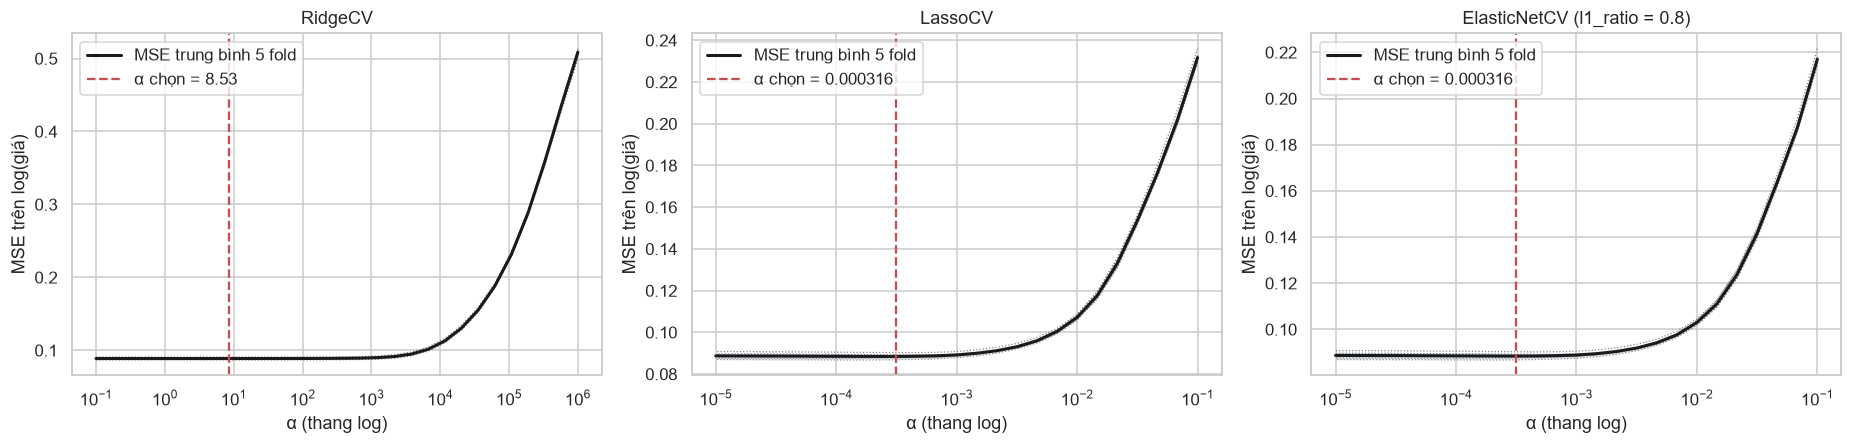

In [16]:
def enet_curve(model, ratio_idx):
    a = np.asarray(model.alphas_)
    return (a[ratio_idx] if a.ndim == 2 else a), model.mse_path_[ratio_idx]


best_ratio_idx = L1_RATIOS.index(enet.l1_ratio_)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

for ax, (title, alphas, mse, best) in zip(axes, [
        ("RidgeCV", RIDGE_ALPHAS, ridge_cv_mse, ridge.alpha_),
        ("LassoCV", lasso.alphas_, lasso.mse_path_, lasso.alpha_),
        (f"ElasticNetCV (l1_ratio = {enet.l1_ratio_})", *enet_curve(enet, best_ratio_idx), enet.alpha_)]):
    mean, std = mse.mean(axis=1), mse.std(axis=1)
    ax.semilogx(alphas, mse, ":", lw=.8, color="gray")
    ax.semilogx(alphas, mean, "k", lw=2, label="MSE trung bình 5 fold")
    ax.fill_between(alphas, mean - std, mean + std, alpha=.2)
    ax.axvline(best, color="C3", ls="--", label=f"α chọn = {best:.3g}")
    ax.set(title=title, xlabel="α (thang log)", ylabel="MSE trên log(giá)")
    ax.legend()
savefig("05_cv_alpha")

In [17]:
# Elastic Net: MSE CV nhỏ nhất theo từng l1_ratio
pd.Series(enet.mse_path_.mean(axis=2).min(axis=1), index=L1_RATIOS,
          name="MSE CV tốt nhất").rename_axis("l1_ratio").to_frame().T

l1_ratio,0.2,0.5,0.8
MSE CV tốt nhất,0.08849,0.08845,0.08844


---
# Phần 4. Đánh giá mô hình
Mô hình dự đoán $\widehat{\log y}$, ta đổi về VND bằng $\hat y = e^{\widehat{\log y}}$ rồi tính:
- $\text{MAE} = \frac1n\sum|y_i - \hat y_i|$: sai số tuyệt đối trung bình (tỷ VND), dễ diễn giải
- $\text{RMSE} = \sqrt{\frac1n\sum(y_i-\hat y_i)^2}$: phạt nặng sai số lớn, nhạy với nhà giá cao
- $\text{MAPE} = \frac{100\%}{n}\sum\left|\frac{y_i-\hat y_i}{y_i}\right|$: sai số tương đối, so sánh được giữa nhà rẻ và nhà đắt
- Thêm $R^2$ và RMSE trên thang log (chính là đại lượng mô hình tối ưu)

So sánh sai số **train và test** để đánh giá mức độ quá khớp.

In [18]:
def evaluate(pipe, X, y_log):
    pred_log = pipe.predict(X)
    y, pred = np.exp(y_log), np.exp(pred_log)
    return {"MAE (tỷ)": mean_absolute_error(y, pred) / 1e9,
            "RMSE (tỷ)": np.sqrt(mean_squared_error(y, pred)) / 1e9,
            "MAPE (%)": mean_absolute_percentage_error(y, pred) * 100,
            "R² (log)": r2_score(y_log, pred_log),
            "RMSE (log)": np.sqrt(mean_squared_error(y_log, pred_log))}


rows = []
for name_, pipe in fitted.items():
    r_tr = evaluate(pipe, X_train, y_train)
    r_te = evaluate(pipe, X_test, y_test)
    m = pipe.named_steps["model"]
    rows.append({"Mô hình": name_,
                 "α": getattr(m, "alpha_", np.nan),
                 "Số hệ số ≠ 0": (m.coef_ != 0).sum() if hasattr(m, "coef_") else np.nan,
                 **{f"{k} test": v for k, v in r_te.items()},
                 "MAPE (%) train": r_tr["MAPE (%)"],
                 "RMSE (log) train": r_tr["RMSE (log)"],
                 "Thời gian (s)": fit_time[name_]})
results = pd.DataFrame(rows).set_index("Mô hình")
results.to_csv(FIG_DIR / "ket_qua.csv")
results

,α,Số hệ số ≠ 0,MAE (tỷ) test,RMSE (tỷ) test,MAPE (%) test,R² (log) test,RMSE (log) test,MAPE (%) train,RMSE (log) train,Thời gian (s)
Mô hình,,,,,,,,,,
Linear Regression,NaN,"1,407",4.235,35.88,26.13,0.8704,0.3081,22.59,0.2883,3.986
Ridge,8.532,"1,407",4.004,10.82,24.26,0.8751,0.3025,22.61,0.2883,89.79
Lasso,0.0003162,"1,152",4.011,10.89,24.19,0.8752,0.3024,22.69,0.2896,47.96
Elastic Net,0.0003162,"1,188",4.009,10.88,24.2,0.8752,0.3024,22.67,0.2894,106.6
Random Forest,NaN,NaN,4.488,13.73,23.09,0.864,0.3156,14.6,0.2005,47.34


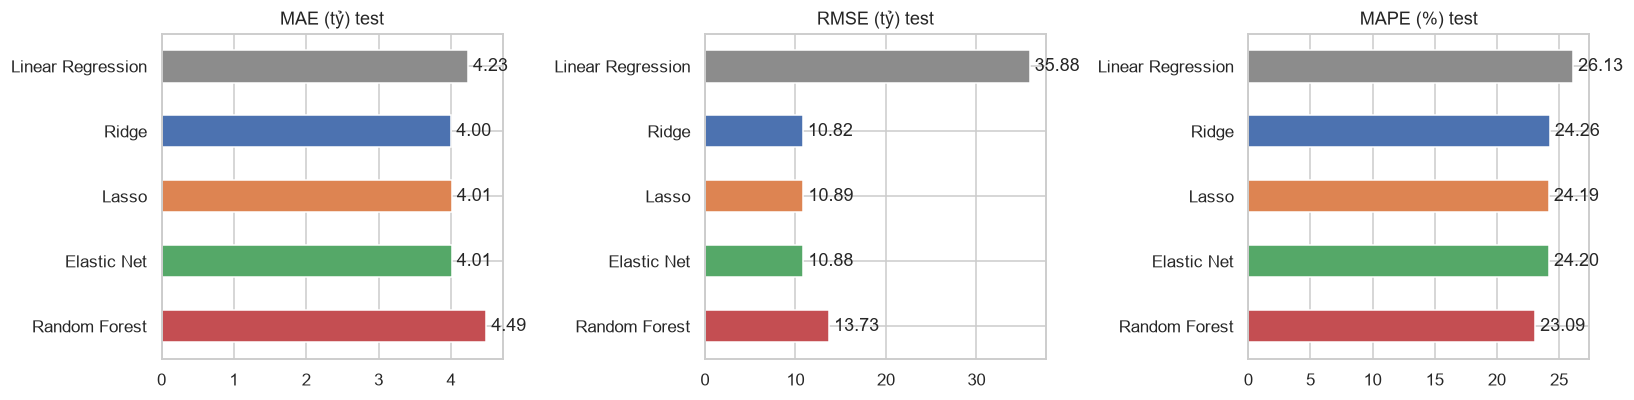

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
colors = ["C7", "C0", "C1", "C2", "C3"]
for ax, metric in zip(axes, ["MAE (tỷ) test", "RMSE (tỷ) test", "MAPE (%) test"]):
    results[metric].plot.barh(ax=ax, color=colors)
    ax.set(title=metric, ylabel="")
    for i, v in enumerate(results[metric]):
        ax.text(v, i, f" {v:.2f}", va="center")
    ax.invert_yaxis()
savefig("06_so_sanh_metric")

### 4.1. Sai số theo từng loại hình

In [20]:
by_type = []
for t in PROPERTY_TYPES:
    mask = (test_df["property_type_name"] == t).to_numpy()
    for name_ in ["Lasso", "Random Forest"]:
        r = evaluate(fitted[name_], X_test[mask], y_test[mask])
        by_type.append({"Loại hình": t, "Mô hình": name_, "n": mask.sum(), **r})
pd.DataFrame(by_type).set_index(["Loại hình", "Mô hình"])

n  MAE (tỷ)  RMSE (tỷ)  MAPE (%)  \
Loại hình            Mô hình                                                
Nhà                  Lasso          139240     4.374      11.72      25.3   
                     Random Forest  139240     4.903      14.92     24.12   
Căn hộ chung cư      Lasso           66554     1.659      3.836     21.09   
                     Random Forest   66554     1.659      3.924     19.55   
Biệt thự/Nhà liền kề Lasso           14887     11.12      20.21     27.66   
                     Random Forest   14887     13.25      25.37     29.21   

                                    R² (log)  RMSE (log)  
Loại hình            Mô hình                              
Nhà                  Lasso            0.8569       0.309  
                     Random Forest    0.8406      0.3261  
Căn hộ chung cư      Lasso            0.7896      0.2784  
                     Random Forest    0.8022        0.27  
Biệt thự/Nhà liền kề Lasso            0.7837      0.3403  
                     Random Forest    0.7079      0.3956

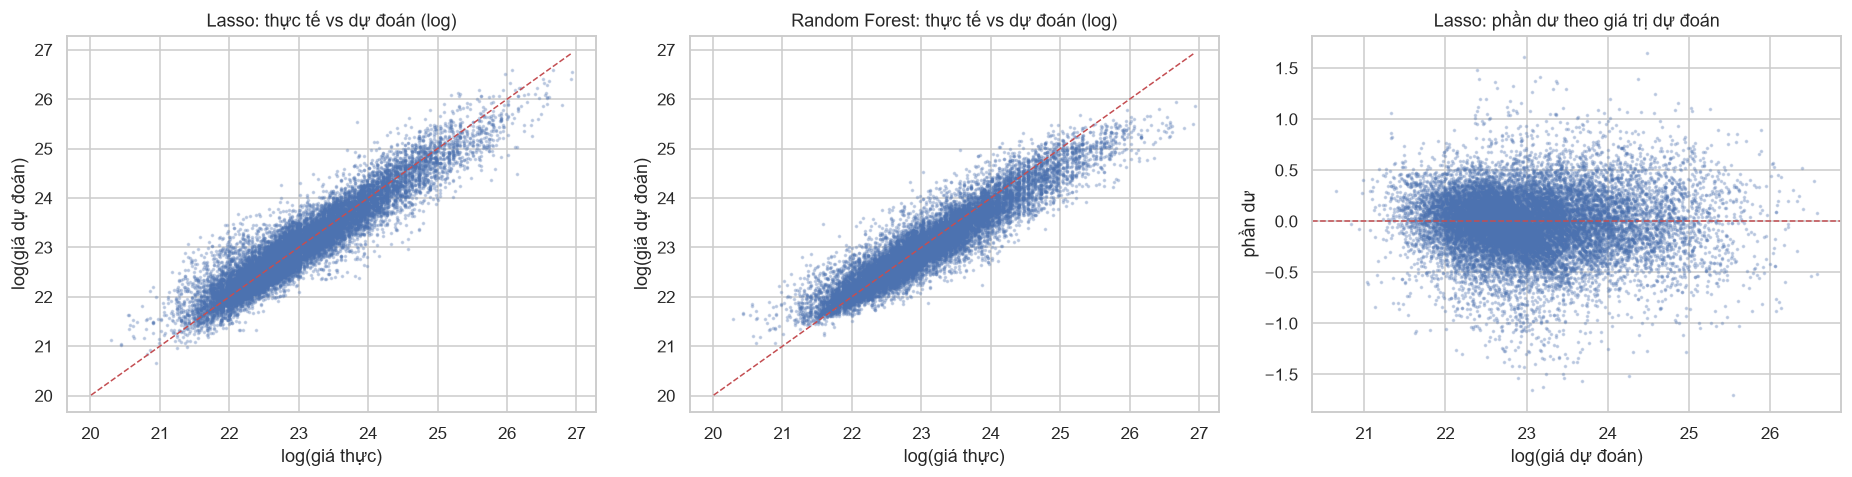

In [21]:
pred_lasso = fitted["Lasso"].predict(X_test)
pred_rf = fitted["Random Forest"].predict(X_test)
idx = np.random.default_rng(RANDOM_STATE).choice(len(y_test), 20_000, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, pred, title in [(axes[0], pred_lasso, "Lasso"), (axes[1], pred_rf, "Random Forest")]:
    ax.scatter(y_test[idx], pred[idx], s=2, alpha=.25)
    lim = [y_test.min(), y_test.max()]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{title}: thực tế vs dự đoán (log)", xlabel="log(giá thực)", ylabel="log(giá dự đoán)")
resid = y_test - pred_lasso
axes[2].scatter(pred_lasso[idx], resid[idx], s=2, alpha=.25)
axes[2].axhline(0, color="r", ls="--", lw=1)
axes[2].set(title="Lasso: phần dư theo giá trị dự đoán", xlabel="log(giá dự đoán)", ylabel="phần dư")
savefig("07_du_doan")

---
# Phần 5. Đường đi hệ số (coefficient path) và lựa chọn đặc trưng của Lasso
Huấn luyện lại Ridge, Lasso, Elastic Net trên **toàn bộ lưới α** (đi từ α lớn đến α nhỏ, dùng `warm_start` để mỗi lần khởi tạo từ nghiệm trước) và vẽ giá trị từng hệ số (đã chuẩn hóa) theo α.
- **Ridge:** mọi hệ số co dần, mượt về 0 nhưng không đúng bằng 0.
- **Lasso:** hệ số lần lượt "rơi" về **đúng 0** khi α tăng; đặc trưng nào tồn tại lâu nhất là đặc trưng quan trọng nhất.
- **Elastic Net:** trung gian, các biến tương quan rời mô hình theo nhóm.

Để vẽ nhanh, path được tính trên 100.000 mẫu con của tập train.

In [22]:
path_idx = np.random.default_rng(RANDOM_STATE).choice(Xs_train.shape[0], min(100_000, Xs_train.shape[0]),
                                                      replace=False)
Xp, yp = Xs_train[path_idx], y_train[path_idx]


def coef_path(model, alphas):
    """Huấn luyện model lần lượt với α giảm dần, trả về (alphas, coefs[p, n_alphas])."""
    alphas = np.sort(alphas)[::-1]
    coefs = []
    for a in alphas:
        model.set_params(alpha=a).fit(Xp, yp)
        coefs.append(model.coef_.copy())
    return alphas, np.array(coefs).T


t0 = time.time()
alphas_l, coefs_l = coef_path(Lasso(warm_start=True, precompute=True, max_iter=3000, tol=1e-3), np.logspace(-5, 0, 40))
alphas_e, coefs_e = coef_path(ElasticNet(l1_ratio=0.5, warm_start=True, precompute=True, max_iter=3000, tol=1e-3),
                              np.logspace(-5, 0, 40))
alphas_r, coefs_r = coef_path(Ridge(), np.logspace(0, 8, 40))
print(f"Tính coefficient path: {time.time() - t0:.0f}s")

Tính coefficient path: 80s


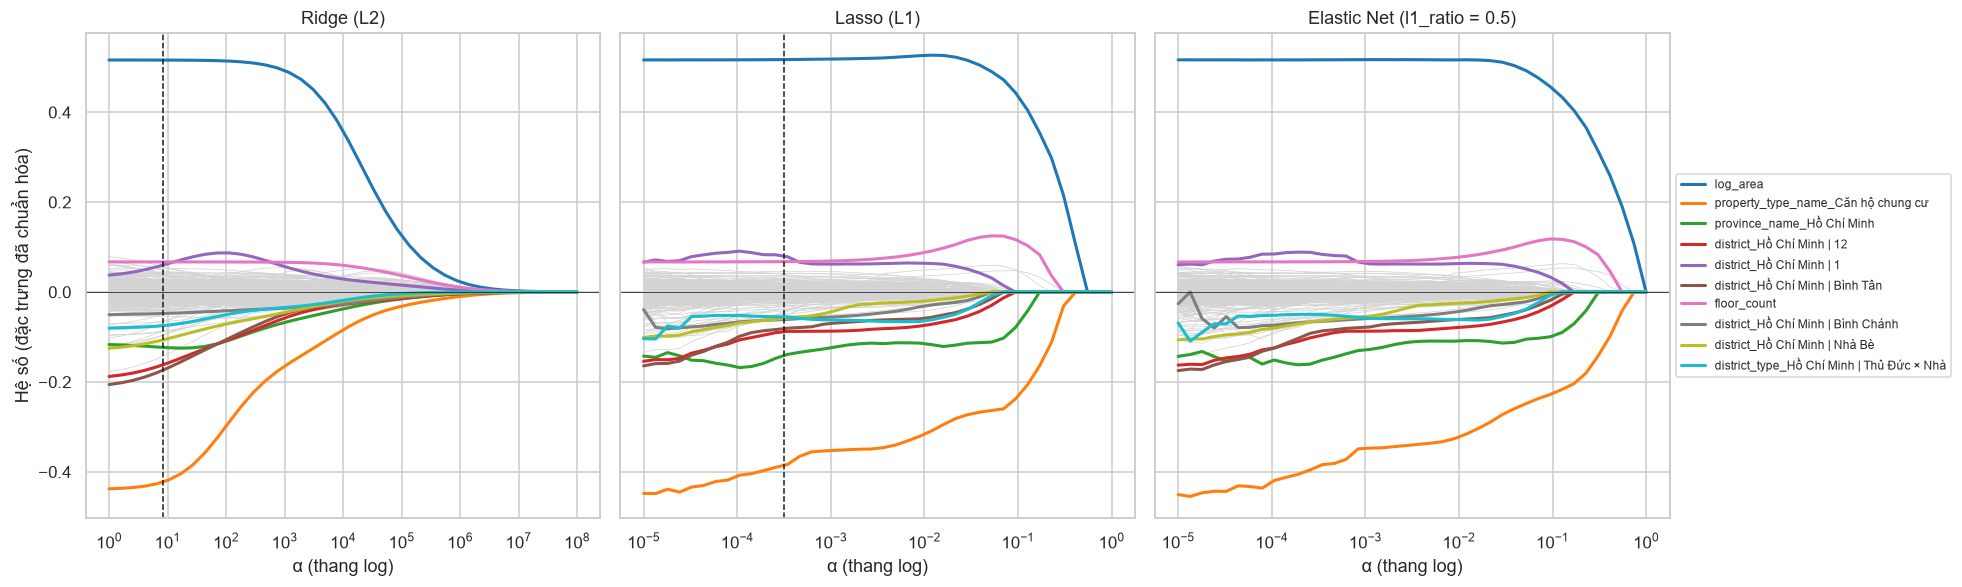

In [23]:
# Tô màu 10 đặc trưng có |hệ số| lớn nhất trong mô hình Lasso đã chọn
top_feats = np.argsort(-np.abs(lasso.coef_))[:10]
palette = sns.color_palette("tab10", 10)
short = lambda f: f.split("__", 1)[1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, alphas, coefs, title, best in [
        (axes[0], alphas_r, coefs_r, "Ridge (L2)", ridge.alpha_),
        (axes[1], alphas_l, coefs_l, "Lasso (L1)", lasso.alpha_),
        (axes[2], alphas_e, coefs_e, "Elastic Net (l1_ratio = 0.5)", None)]:
    ax.semilogx(alphas, coefs.T, color="lightgray", lw=.5)
    for c, j in zip(palette, top_feats):
        ax.semilogx(alphas, coefs[j], color=c, lw=2, label=short(feature_names[j]))
    if best is not None:
        ax.axvline(best, color="k", ls="--", lw=1)
    ax.axhline(0, color="k", lw=.5)
    ax.set(title=title, xlabel="α (thang log)")
axes[0].set_ylabel("Hệ số (đặc trưng đã chuẩn hóa)")
axes[2].legend(loc="center left", bbox_to_anchor=(1, .5), fontsize=8)
savefig("08_coefficient_path")

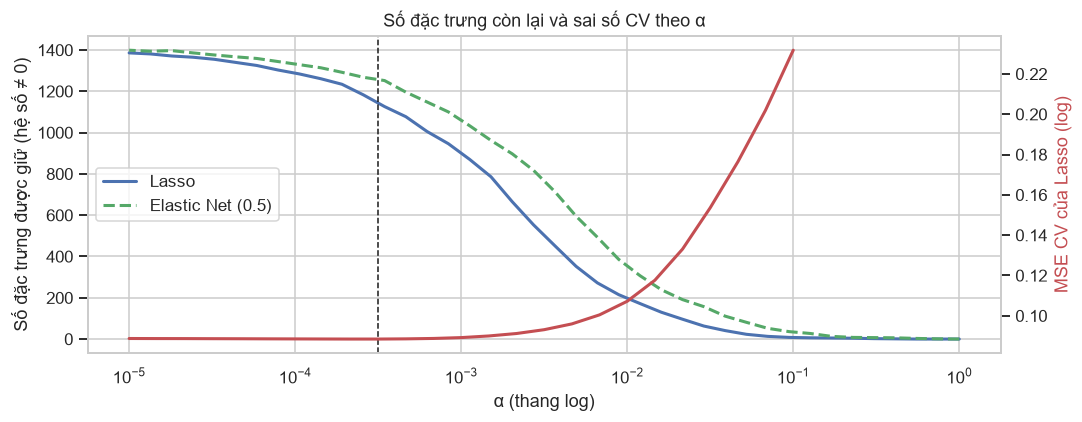

In [24]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.semilogx(alphas_l, (coefs_l != 0).sum(axis=0), "C0", lw=2, label="Lasso")
ax1.semilogx(alphas_e, (coefs_e != 0).sum(axis=0), "C2", lw=2, ls="--", label="Elastic Net (0.5)")
ax1.set(xlabel="α (thang log)", ylabel="Số đặc trưng được giữ (hệ số ≠ 0)")
ax1.legend(loc="center left")
ax2 = ax1.twinx()
ax2.semilogx(lasso.alphas_, lasso.mse_path_.mean(axis=1), "C3", lw=2)
ax2.set_ylabel("MSE CV của Lasso (log)", color="C3")
ax2.grid(False)
ax1.axvline(lasso.alpha_, color="k", ls="--", lw=1)
ax1.set_title("Số đặc trưng còn lại và sai số CV theo α")
savefig("09_lasso_sparsity")

### 5.1. Lasso giữ/loại đặc trưng thuộc nhóm nào?

In [25]:
coef_df = pd.DataFrame({"Linear Regression": fitted["Linear Regression"].named_steps["model"].coef_,
                        "Ridge": ridge.coef_, "Lasso": lasso.coef_, "Elastic Net": enet.coef_},
                       index=feature_names)
coef_df["nhóm"] = groups

summary = coef_df.groupby("nhóm").agg(
    tong=("Lasso", "size"),
    lasso_giu=("Lasso", lambda s: (s != 0).sum()),
    enet_giu=("Elastic Net", lambda s: (s != 0).sum()))
summary["% Lasso loại"] = (1 - summary["lasso_giu"] / summary["tong"]) * 100
summary.columns = ["Tổng số", "Lasso giữ", "Elastic Net giữ", "% Lasso loại"]
summary.sort_values("Tổng số", ascending=False)

,Tổng số,Lasso giữ,Elastic Net giữ,% Lasso loại
nhóm,,,,
text,1000,806,831,19.4
ward,241,217,226,9.959
district_type,86,65,64,24.42
district,38,30,31,21.05
num,12,12,12,0
project,11,10,10,9.091
direction,8,5,7,37.5
kw,8,4,4,50
property_type_name,2,2,2,0


In [26]:
w = coef_df[["Linear Regression", "Ridge", "Lasso", "Elastic Net"]]
pd.DataFrame({"Chuẩn L2 ‖w‖₂": np.linalg.norm(w, axis=0),
              "Chuẩn L1 ‖w‖₁": np.abs(w).sum(axis=0),
              "Số hệ số ≠ 0": (w != 0).sum(axis=0)}, index=w.columns).T

,Linear Regression,Ridge,Lasso,Elastic Net
Chuẩn L2 ‖w‖₂,109.6,0.8792,0.7457,0.7509
Chuẩn L1 ‖w‖₁,713.4,11.45,7.158,7.413
Số hệ số ≠ 0,"1,407","1,407","1,152","1,188"


### 5.2. Thứ tự đặc trưng đi vào mô hình Lasso
Với mỗi đặc trưng, tìm **α lớn nhất mà hệ số còn khác 0**, tức thời điểm nó "đi vào" path khi α giảm dần. Đặc trưng đi vào sớm (α lớn) là đặc trưng có sức giải thích mạnh nhất.

In [27]:
nz = coefs_l != 0
enter_alpha = np.where(nz.any(axis=1), np.where(nz, alphas_l, 0).max(axis=1), 0)
order = pd.DataFrame({"đặc trưng": [short(f) for f in feature_names], "nhóm": groups.values,
                      "α vào mô hình": enter_alpha,
                      "hệ số Lasso (α tối ưu)": lasso.coef_,
                      "hệ số Ridge (α tối ưu)": ridge.coef_}).sort_values("α vào mô hình", ascending=False)
order.head(25)

,đặc trưng,nhóm,α vào mô hình,hệ số Lasso (α tối ưu),hệ số Ridge (α tối ưu)
0,log_area,num,0.4125,0.5172,0.5162
20,property_type_name_Căn hộ chung cư,property_type_name,0.307,-0.3883,-0.4224
3,floor_count,num,0.2285,0.06761,0.06704
7,missingindicator_bedroom_count,num,0.2285,0.02679,0.02555
12,kw_mat_tien,kw,0.1701,0,-0.007834
22,province_name_Hồ Chí Minh,province_name,0.1266,-0.1437,-0.1232
954,phố,text,0.09427,0.007667,0.007295
8,missingindicator_bathroom_count,num,0.09427,0.01961,0.01995
42,district_Hồ Chí Minh | 12,district,0.07017,-0.08663,-0.1614
1105,thự,text,0.07017,0.004583,0.03875


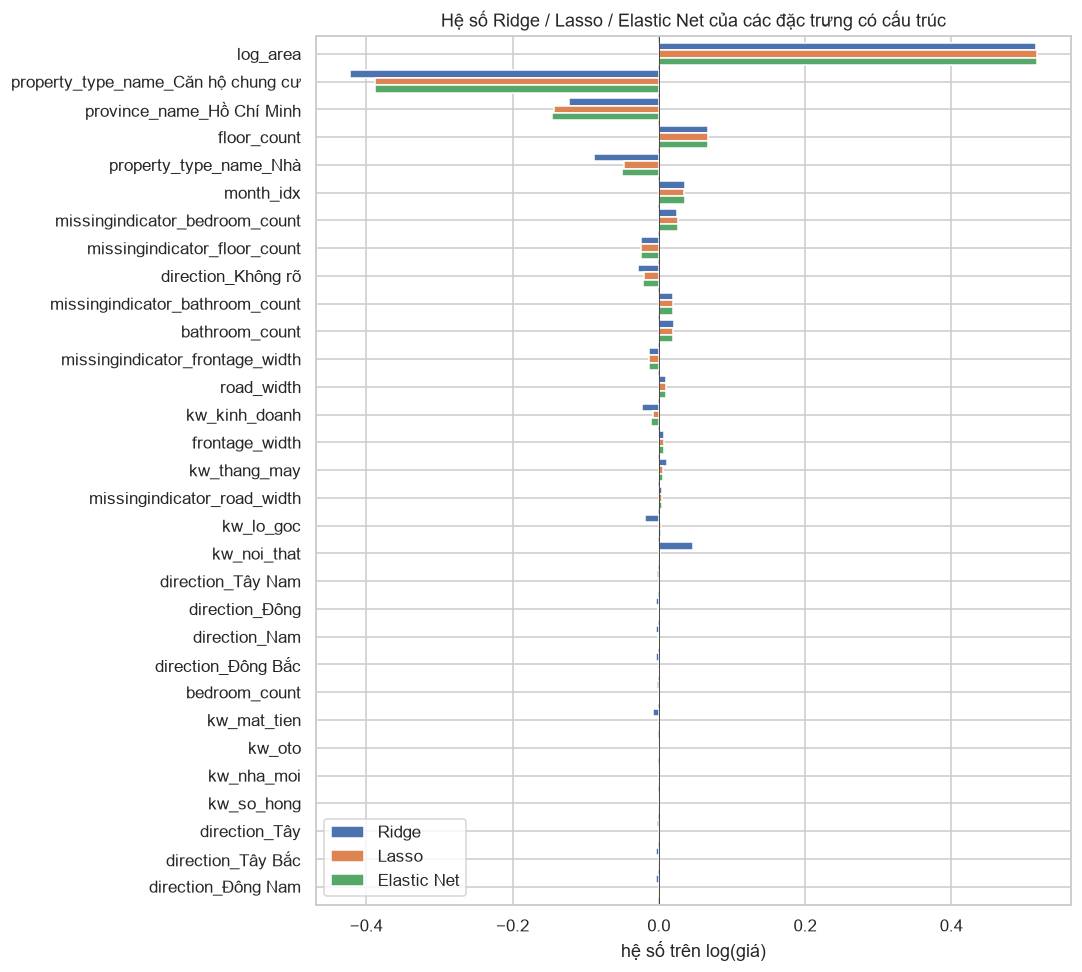

In [28]:
struct = coef_df[coef_df["nhóm"].isin(["num", "kw", "property_type_name", "province_name", "direction"])]
struct = struct.reindex(struct["Lasso"].abs().sort_values(ascending=False).index)
struct.index = [short(f) for f in struct.index]

fig, ax = plt.subplots(figsize=(10, 9))
struct[["Ridge", "Lasso", "Elastic Net"]].plot.barh(ax=ax, width=.8)
ax.invert_yaxis()
ax.axvline(0, color="k", lw=.5)
ax.set(title="Hệ số Ridge / Lasso / Elastic Net của các đặc trưng có cấu trúc", xlabel="hệ số trên log(giá)")
savefig("10_he_so")

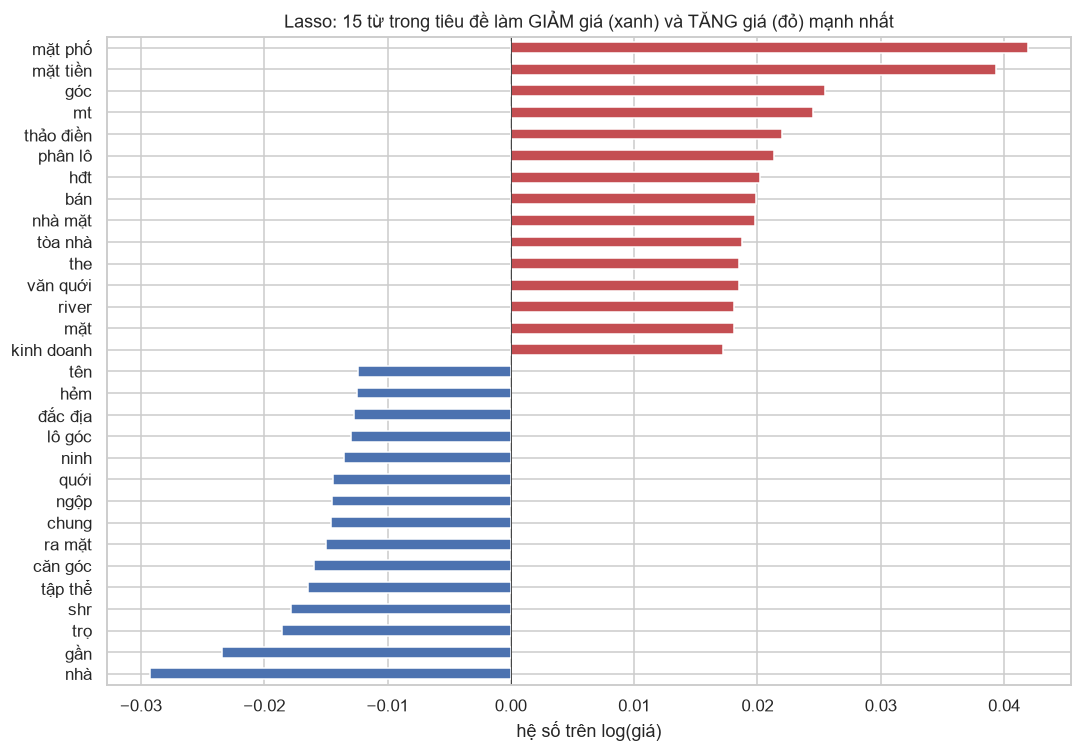

Lasso giữ 806/1000 từ trong tiêu đề


In [29]:
words = coef_df.loc[coef_df["nhóm"] == "text", "Lasso"]
words.index = [short(f) for f in words.index]
words = words[words != 0].sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
pd.concat([words.head(15), words.tail(15)]).plot.barh(ax=ax, color=["C0"] * 15 + ["C3"] * 15)
ax.axvline(0, color="k", lw=.5)
ax.set(title="Lasso: 15 từ trong tiêu đề làm GIẢM giá (xanh) và TĂNG giá (đỏ) mạnh nhất",
       xlabel="hệ số trên log(giá)")
savefig("11_tu_khoa_lasso")
print(f"Lasso giữ {len(words)}/{(groups == 'text').sum()} từ trong tiêu đề")

### 5.3. Đánh đổi giữa độ thưa và độ chính xác
Huấn luyện Lasso tại một số α cố định và đo sai số trên **tập test**, để thấy với α lớn hơn α tối ưu ta có thể bỏ phần lớn đặc trưng mà sai số chỉ tăng nhẹ.

In [30]:
trade = []
for a in sorted({1e-5, lasso.alpha_, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2}):
    p_ = Pipeline([("pre", make_preprocessor()),
                   ("model", Lasso(alpha=a, precompute=True, max_iter=3000, tol=1e-3))]).fit(X_train, y_train)
    trade.append({"α": a, "Số đặc trưng ≠ 0": (p_.named_steps["model"].coef_ != 0).sum(),
                  **evaluate(p_, X_test, y_test)})
trade = pd.DataFrame(trade).set_index("α")
trade

,Số đặc trưng ≠ 0,MAE (tỷ),RMSE (tỷ),MAPE (%),R² (log),RMSE (log)
α,,,,,,
1e-05,1388,4.003,10.82,24.26,0.875,0.3025
0.0001,1290,4.004,10.84,24.23,0.8752,0.3023
0.0003,1158,4.01,10.89,24.19,0.8752,0.3024
0.0003162,1151,4.011,10.89,24.19,0.8752,0.3024
0.001,904,4.041,11.03,24.21,0.8742,0.3036
0.003,521,4.155,11.37,24.56,0.8692,0.3095
0.01,196,4.526,12.35,26.08,0.8492,0.3324
0.03,59,5.414,14.64,30.59,0.7857,0.3962


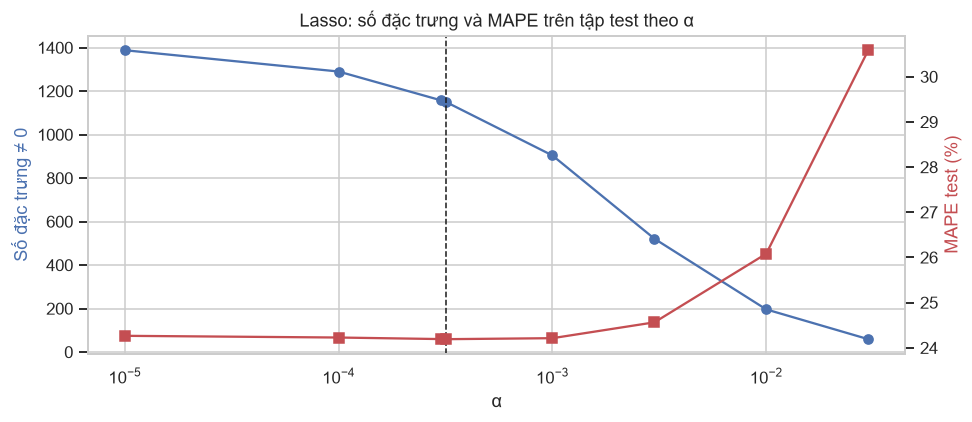

In [31]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.semilogx(trade.index, trade["Số đặc trưng ≠ 0"], "o-C0")
ax1.set(xlabel="α", ylabel="Số đặc trưng ≠ 0")
ax1.yaxis.label.set_color("C0")
ax2 = ax1.twinx()
ax2.semilogx(trade.index, trade["MAPE (%)"], "s-C3")
ax2.set_ylabel("MAPE test (%)", color="C3")
ax2.grid(False)
ax1.axvline(lasso.alpha_, color="k", ls="--", lw=1)
ax1.set_title("Lasso: số đặc trưng và MAPE trên tập test theo α")
savefig("12_lasso_tradeoff")

### 5.4. Khi nào chính quy hóa thật sự cần thiết? Ảnh hưởng của số mẫu n
Ở trên, với $n = 50\,000 \gg p$, OLS gần như không quá khớp nên Ridge/Lasso chỉ hơn rất ít. Để thấy rõ vai trò của α, ta **giữ nguyên p** (dùng pipeline đã fit ở mục 2.9) và huấn luyện trên các tập con **n = 1k, 2k, 5k, 20k** mẫu, rồi so sánh RMSE (log) trên 50.000 tin của tập test.

Kỳ vọng từ lý thuyết:
- n nhỏ: nhiều cột one-hot/từ hiếm chỉ có vài giá trị khác 0, $X^\top X$ gần suy biến, hệ số OLS **bùng nổ**, sai số test rất lớn.
- Ridge/Lasso giữ sai số ổn định. α được CV chọn **giảm dần khi n tăng**, vì càng nhiều dữ liệu thì phương sai ước lượng càng nhỏ và càng cần ít chính quy hóa.

In [32]:
rng = np.random.default_rng(RANDOM_STATE)
te_idx = rng.choice(len(X_test), 50_000, replace=False)
Xs_te, y_te = pre_tr.transform(X_test.iloc[te_idx]), y_test[te_idx]


def rmse_log(model, X, y):
    return np.sqrt(mean_squared_error(y, model.predict(X)))


size_rows = []
for n in [1_000, 2_000, 5_000, 20_000]:
    idx = rng.choice(Xs_train.shape[0], n, replace=False)
    Xn, yn = Xs_train[idx], y_train[idx]
    ols = LinearRegression().fit(Xn, yn)
    rcv = RidgeCV(alphas=RIDGE_ALPHAS).fit(Xn, yn)           # leave-one-out (nhanh khi n nhỏ)
    lcv = LassoCV(alphas=np.logspace(-4, 0, 15), cv=cv, n_jobs=4, max_iter=3000, tol=1e-3).fit(Xn, yn)
    size_rows.append({"n": n, "OLS": rmse_log(ols, Xs_te, y_te), "Ridge": rmse_log(rcv, Xs_te, y_te),
                      "Lasso": rmse_log(lcv, Xs_te, y_te), "α Ridge": rcv.alpha_, "α Lasso": lcv.alpha_,
                      "Lasso giữ": (lcv.coef_ != 0).sum(), "‖w‖₂ OLS": np.linalg.norm(ols.coef_)})

X_te_raw = X_test.iloc[te_idx]
size_rows.append({"n": len(X_train),
                  **{k: rmse_log(fitted[k2], X_te_raw, y_te)
                     for k, k2 in [("OLS", "Linear Regression"), ("Ridge", "Ridge"), ("Lasso", "Lasso")]},
                  "α Ridge": ridge.alpha_, "α Lasso": lasso.alpha_, "Lasso giữ": (lasso.coef_ != 0).sum(),
                  "‖w‖₂ OLS": np.linalg.norm(fitted["Linear Regression"].named_steps["model"].coef_)})
by_size = pd.DataFrame(size_rows).set_index("n")
by_size

,OLS,Ridge,Lasso,α Ridge,α Lasso,Lasso giữ,‖w‖₂ OLS
n,,,,,,,
1000,0.8771,0.4791,0.372,417.5,0.01,313,1.156
2000,2.2,0.4079,0.3431,239.5,0.01,262,10.77
5000,8.171,0.3367,0.3224,239.5,0.005179,427,393.3
20000,0.3165,0.3098,0.3075,137.4,0.0007197,1020,12.9
50000,0.3149,0.3025,0.3023,8.532,0.0003162,1152,109.6


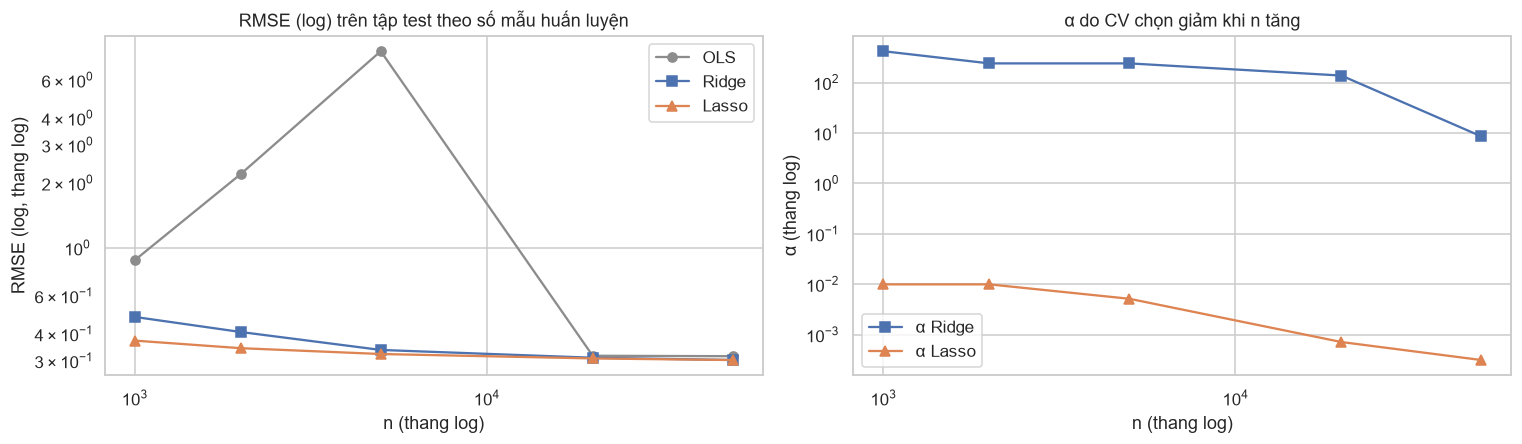

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for col, style in [("OLS", "o-C7"), ("Ridge", "s-C0"), ("Lasso", "^-C1")]:
    axes[0].loglog(by_size.index, by_size[col], style, label=col)
axes[0].set(title="RMSE (log) trên tập test theo số mẫu huấn luyện", xlabel="n (thang log)", ylabel="RMSE (log, thang log)")
axes[0].legend()
axes[1].loglog(by_size.index, by_size["α Ridge"], "s-C0", label="α Ridge")
axes[1].loglog(by_size.index, by_size["α Lasso"], "^-C1", label="α Lasso")
axes[1].set(title="α do CV chọn giảm khi n tăng", xlabel="n (thang log)", ylabel="α (thang log)")
axes[1].legend()
savefig("13_theo_so_mau")

### 5.5. Đối chiếu: độ quan trọng đặc trưng của Random Forest

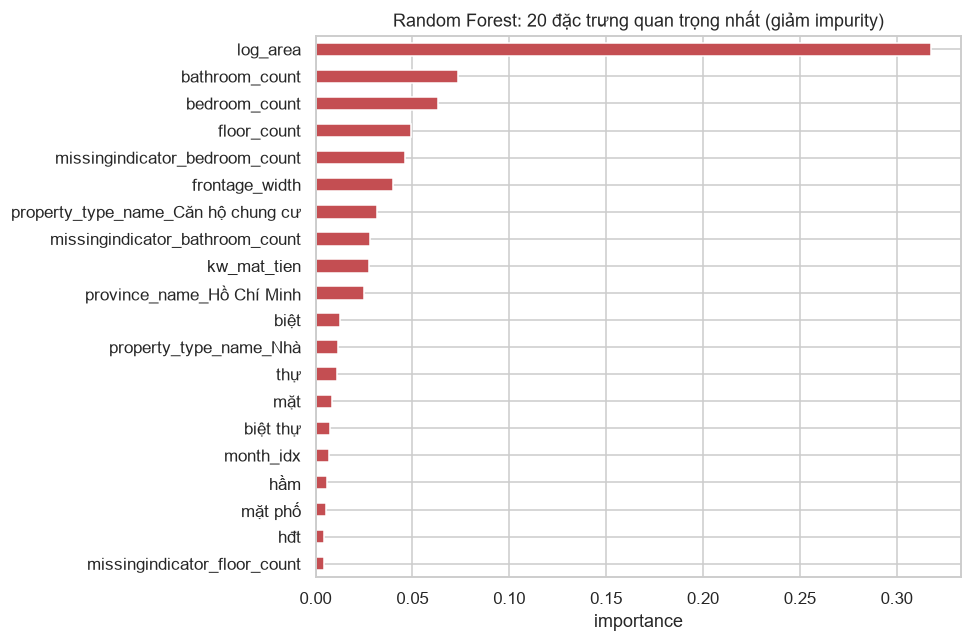

In [34]:
rf = fitted["Random Forest"].named_steps["model"]
imp = pd.Series(rf.feature_importances_, index=[short(f) for f in feature_names])
fig, ax = plt.subplots(figsize=(9, 6))
imp.sort_values().tail(20).plot.barh(ax=ax, color="C3")
ax.set(title="Random Forest: 20 đặc trưng quan trọng nhất (giảm impurity)", xlabel="importance")
savefig("14_rf_importance")

---
# Phần 6. Demo: dự đoán giá một căn nhà
### 6.1. Lưu và nạp lại mô hình
Các pipeline đã huấn luyện (gồm cả bước tiền xử lý) được lưu ra thư mục `models/` bằng `joblib`. Khi dùng lại, chỉ cần `joblib.load(...)` mà không phải huấn luyện lại.

In [35]:
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
for key, name_ in [("lasso", "Lasso"), ("ridge", "Ridge"), ("random_forest", "Random Forest")]:
    joblib.dump(fitted[name_], MODEL_DIR / f"{key}.joblib", compress=3)
    print(f"Đã lưu {MODEL_DIR / f'{key}.joblib'} ({(MODEL_DIR / f'{key}.joblib').stat().st_size / 1e6:.1f} MB)")

demo_models = {name_: joblib.load(MODEL_DIR / f"{key}.joblib")
               for key, name_ in [("lasso", "Lasso"), ("ridge", "Ridge"), ("random_forest", "Random Forest")]}

Đã lưu models\lasso.joblib (0.1 MB)
Đã lưu models\ridge.joblib (0.1 MB)
Đã lưu models\random_forest.joblib (38.6 MB)


### 6.2. Hàm dự đoán
`du_doan_gia(...)` nhận thông tin căn nhà, tạo đúng các đặc trưng như ở Phần 2 (log diện tích, cờ từ khóa và số tầng lấy từ tiêu đề, chuỗi quận/phường, tháng đăng…), rồi trả về giá dự đoán (tỷ VND) của từng mô hình.
- Thông tin nào không biết thì bỏ trống (`None`). Pipeline sẽ điền trung vị và bật cột đánh dấu "thiếu", giống hệt lúc huấn luyện.
- Quận/phường/dự án không có trong dữ liệu huấn luyện sẽ được bỏ qua (`handle_unknown="ignore"`).

In [36]:
def tao_dac_trung(tinh, quan, loai_hinh, dien_tich, phuong=None, phong_ngu=None, phong_tam=None,
                  so_tang=None, mat_tien=None, duong_rong=None, huong=None, du_an=None,
                  tieu_de="", ngay_dang="2026-03-15"):
    """Tạo 1 dòng DataFrame có đúng các cột FEATURES mà pipeline cần."""
    title = tieu_de.lower()
    if loai_hinh == "Căn hộ chung cư":
        so_tang = None                                   # giống bước 2.3: căn hộ không dùng số tầng
    elif so_tang is None:                                # giống bước 2.4: lấy số tầng từ tiêu đề
        m_tang, m_lau = re.search(r"(\d{1,2})\s*tầng", title), re.search(r"(\d{1,2})\s*lầu", title)
        if m_tang:
            so_tang = int(m_tang.group(1))
        elif m_lau:
            so_tang = int(m_lau.group(1)) + 1
    huong = (huong or "").replace(" - ", " ")
    district = f"{tinh} | {quan or 'Không rõ'}"
    ngay = pd.Timestamp(ngay_dang)
    row = {
        "log_area": np.log(dien_tich),
        "bedroom_count": phong_ngu, "bathroom_count": phong_tam, "floor_count": so_tang,
        "frontage_width": mat_tien, "road_width": duong_rong,
        "month_idx": (ngay.year - 2025) * 12 + ngay.month - 6,
        **{k: int(bool(re.search(p, title))) for k, p in KEYWORDS.items()},
        "property_type_name": loai_hinh, "province_name": tinh, "district": district,
        "direction": huong if huong in VALID_DIRECTIONS else "Không rõ",
        "ward": f"{district} | {phuong or 'Không rõ'}",
        "project": du_an or "Không thuộc dự án",
        "district_type": f"{district} × {loai_hinh}",
        "name": tieu_de,
    }
    return pd.DataFrame([row])[FEATURES].astype({c: float for c in NUM_COLS})


def du_doan_gia(**thong_tin):
    """Trả về giá dự đoán (tỷ VND) của từng mô hình."""
    X = tao_dac_trung(**thong_tin)
    return {ten: float(np.exp(m.predict(X)[0])) / 1e9 for ten, m in demo_models.items()}


du_doan_gia(tinh="Hồ Chí Minh", quan="Gò Vấp", loai_hinh="Nhà", dien_tich=50, phong_ngu=4, phong_tam=4,
            tieu_de="Bán nhà hẻm xe hơi 4 tầng, sổ hồng riêng, gần chợ")

{'Lasso': 4.846715392,
 'Ridge': 4.883340288,
 'Random Forest': 7.128757801136147}

### 6.3. Ví dụ một số căn nhà điển hình
Ba ví dụ đầu là ba loại hình khác nhau. Các ví dụ sau giữ nguyên căn nhà ở Gò Vấp và **chỉ thay đổi một yếu tố** (vị trí, diện tích, tiêu đề) để thấy mô hình phản ứng thế nào. Đây cũng là cách diễn giải hệ số của mô hình tuyến tính trên log(giá).

In [37]:
nha_go_vap = dict(tinh="Hồ Chí Minh", quan="Gò Vấp", loai_hinh="Nhà", dien_tich=50, phong_ngu=4, phong_tam=4,
                  tieu_de="Bán nhà hẻm xe hơi 4 tầng, sổ hồng riêng, gần chợ")
vi_du = {
    "Căn hộ 2PN 70m² – Cầu Giấy, HN": dict(tinh="Hà Nội", quan="Cầu Giấy", loai_hinh="Căn hộ chung cư",
                                            dien_tich=70, phong_ngu=2, phong_tam=2, huong="Đông Nam",
                                            tieu_de="Bán căn hộ 2 phòng ngủ full nội thất, tầng trung, view thoáng"),
    "Nhà 4 tầng 50m² – Gò Vấp, HCM": nha_go_vap,
    "Biệt thự 200m² – Long Biên, HN": dict(tinh="Hà Nội", quan="Long Biên", loai_hinh="Biệt thự/Nhà liền kề",
                                             dien_tich=200, phong_ngu=5, phong_tam=5, so_tang=3,
                                             tieu_de="Bán biệt thự song lập, lô góc, view vườn hoa"),
    "↳ cùng nhà, chuyển sang Quận 1": {**nha_go_vap, "quan": "1"},
    "↳ cùng nhà, chuyển sang Bình Tân": {**nha_go_vap, "quan": "Bình Tân"},
    "↳ cùng nhà, diện tích 100m²": {**nha_go_vap, "dien_tich": 100},
    "↳ cùng nhà, tiêu đề ghi 'mặt tiền kinh doanh'": {**nha_go_vap,
                                                     "tieu_de": "Bán nhà mặt tiền kinh doanh 4 tầng, sổ hồng riêng"},
    "↳ cùng nhà, không ghi số phòng": {**nha_go_vap, "phong_ngu": None, "phong_tam": None},
}
demo_table = pd.DataFrame({ten: du_doan_gia(**tt) for ten, tt in vi_du.items()}).T
demo_table.columns = [f"{c} (tỷ)" for c in demo_table.columns]
demo_table

,Lasso (tỷ),Ridge (tỷ),Random Forest (tỷ)
"Căn hộ 2PN 70m² – Cầu Giấy, HN",6.637,6.577,6.138
"Nhà 4 tầng 50m² – Gò Vấp, HCM",4.847,4.883,7.129
"Biệt thự 200m² – Long Biên, HN",53.43,54.04,45.71
"↳ cùng nhà, chuyển sang Quận 1",9.057,9.326,8.107
"↳ cùng nhà, chuyển sang Bình Tân",3.714,3.525,6.178
"↳ cùng nhà, diện tích 100m²",9.05,9.107,10.48
"↳ cùng nhà, tiêu đề ghi 'mặt tiền kinh doanh'",7.644,7.685,9.42
"↳ cùng nhà, không ghi số phòng",5.293,5.324,6.194


### 6.4. Đối chiếu với tin đăng thật trong tập test
Lấy ngẫu nhiên 12 tin trong tập test (tháng 02–03/2026, mô hình chưa từng thấy) và so giá rao bán thật với giá dự đoán.

In [38]:
mau = test_df.sample(12, random_state=7)
X_mau = mau[FEATURES]
doi_chieu = pd.DataFrame({
    "Tiêu đề": mau["name"].str.slice(0, 60),
    "Loại hình": mau["property_type_name"],
    "Quận": mau["district"].str.split(" | ", regex=False).str[-1],
    "DT (m²)": mau["area"],
    "Giá thật (tỷ)": mau["price"] / 1e9,
    "Lasso (tỷ)": np.exp(demo_models["Lasso"].predict(X_mau)) / 1e9,
    "RF (tỷ)": np.exp(demo_models["Random Forest"].predict(X_mau)) / 1e9,
})
doi_chieu["Sai lệch Lasso (%)"] = (doi_chieu["Lasso (tỷ)"] / doi_chieu["Giá thật (tỷ)"] - 1) * 100
doi_chieu["Sai lệch RF (%)"] = (doi_chieu["RF (tỷ)"] / doi_chieu["Giá thật (tỷ)"] - 1) * 100
doi_chieu.reset_index(drop=True)

,Tiêu đề,Loại hình,Quận,DT (m²),Giá thật (tỷ),Lasso (tỷ),RF (tỷ),Sai lệch Lasso (%),Sai lệch RF (%)
0,"HIẾM HỒ TÂY TÒA 7 TẦNG , VÀI BƯỚC RA KHU BẮN P...",Nhà,Tây Hồ,80,38,43.47,25.97,14.39,-31.66
1,"Bán Dãy Trọ 10x40m, 1135 Huỳnh Tấn Phát p.Phú ...",Nhà,7,400,14,29.17,21.7,108.4,55
2,"Giảm 2 tỷ bán nhà đường đôi 40m, KĐT An Hưng 8...",Biệt thự/Nhà liền kề,Hà Đông,82.5,26.5,20.76,20.99,-21.67,-20.81
3,"Bán Nhà riêng 3PN, 2WC, 28m2, 5,65 tỷ tại Tô H...",Nhà,10,28,5.65,5.244,5.01,-7.183,-11.32
4,Căn góc giảm 500tr bán chung cư Phan Xích Long...,Căn hộ chung cư,Phú Nhuận,56,3.6,4.151,3.081,15.29,-14.41
5,Giảm 500 triệu cho căn nhà đẹp chính chủ,Nhà,Gò Vấp,47,9.2,5.851,6.858,-36.4,-25.46
6,CHỈ 3.15 TỶ CÓ NHÀ THỦ ĐỨC 3PN GẦN VINHOMES GR...,Nhà,Thủ Đức,40,3.15,3.267,4.189,3.707,32.98
7,"Bán Mặt Tiền Xuân Thủy , P.Thảo Điền cũ - Gần ...",Nhà,Thủ Đức,240,65,50.66,37.31,-22.06,-42.6
8,Chủ nhà rất thiện chí bán căn hộ toà ICID - Lê...,Căn hộ chung cư,Hà Đông,64.8,4.48,4.353,4.66,-2.836,4.015
9,"Lên sóng siêu phẩm hẻm xe hơi Trần Minh Quyền,...",Nhà,10,64,3.17,13.41,8.355,322.9,163.6


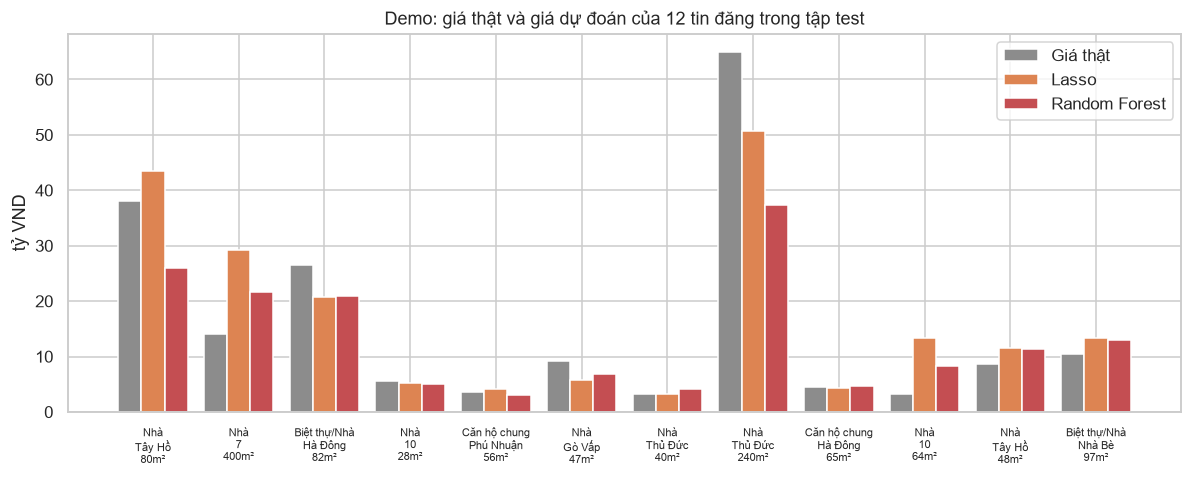

In [39]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(doi_chieu))
ax.bar(x - 0.27, doi_chieu["Giá thật (tỷ)"], 0.27, label="Giá thật", color="C7")
ax.bar(x, doi_chieu["Lasso (tỷ)"], 0.27, label="Lasso", color="C1")
ax.bar(x + 0.27, doi_chieu["RF (tỷ)"], 0.27, label="Random Forest", color="C3")
ax.set_xticks(x, [f"{t[:12]}\n{q}\n{a:.0f}m²" for t, q, a in
                  zip(doi_chieu["Loại hình"], doi_chieu["Quận"], doi_chieu["DT (m²)"])], fontsize=7)
ax.set(title="Demo: giá thật và giá dự đoán của 12 tin đăng trong tập test", ylabel="tỷ VND")
ax.legend()
savefig("15_demo_doi_chieu")

### 6.5. Thử với căn nhà của bạn
Sửa các giá trị dưới đây rồi chạy lại ô. Tên tỉnh dùng "Hồ Chí Minh" hoặc "Hà Nội". Quận ghi như trong dữ liệu, ví dụ "Cầu Giấy", "Gò Vấp", hoặc "7" cho Quận 7. Loại hình là một trong: "Nhà", "Căn hộ chung cư", "Biệt thự/Nhà liền kề".

In [40]:
ket_qua = du_doan_gia(
    tinh="Hà Nội", quan="Thanh Xuân", phuong=None, loai_hinh="Nhà",
    dien_tich=40, phong_ngu=3, phong_tam=3, so_tang=5, mat_tien=4, duong_rong=None,
    huong="Đông Nam", du_an=None,
    tieu_de="Bán nhà ngõ ô tô đỗ cửa, 5 tầng, thang máy, gần phố",
)
for ten, gia in ket_qua.items():
    print(f"{ten:15s}: {gia:6.2f} tỷ VND")

Lasso          :  11.38 tỷ VND
Ridge          :  11.63 tỷ VND
Random Forest  :  10.31 tỷ VND


---
# Phần 7. Kết luận

*(Các con số dưới đây ứng với `TRAIN_SAMPLE = 50_000`, `RANDOM_STATE = 42`; tập test là 220.681 tin đăng tháng 02–03/2026.)*

**1. Tiền xử lý (yêu cầu 2).** Từ 2,13 triệu tin nhà ở tại TP.HCM và Hà Nội, sau khi loại tin không có giá, tin trùng lặp và ngoại lai, còn khoảng 1,47 triệu tin.
- Giá trị thiếu được điền bằng trung vị, kèm cột đánh dấu "thiếu". Số tầng được bổ sung từ tiêu đề.
- Biến phân loại được mã hóa one-hot. Biến đổi log đưa độ lệch của giá từ 6,84 về 0,75.
- Kết quả là 1.407 đặc trưng cho 50.000 mẫu huấn luyện.

**2. So sánh mô hình trên tập test (yêu cầu 3, 4).**

| Mô hình | α (CV chọn) | Số hệ số ≠ 0 | MAE (tỷ) | RMSE (tỷ) | MAPE (%) | R² (log) |
|---|---|---|---|---|---|---|
| Linear Regression | – | 1407 | 4,24 | **35,88** | 26,13 | 0,870 |
| Ridge | 8,53 | 1407 | **4,00** | **10,82** | 24,26 | 0,875 |
| Lasso | 3,2·10⁻⁴ | **1152** | 4,01 | 10,89 | **24,19** | 0,875 |
| Elastic Net (l1_ratio = 0,8) | 3,2·10⁻⁴ | 1188 | 4,01 | 10,88 | 24,20 | 0,875 |
| Random Forest (đối chiếu) | – | – | 4,49 | 13,73 | 23,09 | 0,864 |

- **Chính quy hóa giúp rõ rệt so với OLS.** RMSE của OLS lên tới 35,9 tỷ, gấp hơn 3 lần Ridge/Lasso, vì một số căn bị dự đoán sai cực lớn. Nguyên nhân là hệ số OLS bị "bùng nổ": $\|w\|_2$ = 109,6 so với 0,88 (Ridge) và 0,75 (Lasso). Các cột one-hot hiếm và các đặc trưng tương quan làm $X^\top X$ gần suy biến, đúng như phân tích ở mục 1.1.
- **Ridge, Lasso và Elastic Net cho độ chính xác tương đương**, MAPE khoảng 24,2%. Lasso đạt điều đó với ít hơn 255 đặc trưng.
- **Random Forest** có MAPE thấp nhất (23,1%), nhưng MAE/RMSE và R²(log) kém hơn mô hình tuyến tính có chính quy hóa. RF cũng quá khớp rõ (MAPE train 14,6% so với test 23,1%). RF chỉ tốt hơn ở căn hộ (MAPE 19,6% so với 21,1%), còn với biệt thự/liền kề thì kém hơn (29,2% so với 27,7%).

**3. Vai trò của α và độ phức tạp mô hình (yêu cầu 1, mục 3.1 và 5.4).**
- **Đường cong CV:** gần như phẳng khi α nhỏ, rồi tăng vọt khi α vượt khoảng $10^{3}$ (Ridge) hoặc $10^{-3}$ (Lasso). α lớn làm mô hình dưới khớp: MSE tăng từ 0,089 lên 0,51 với Ridge.
- **α tối ưu của Ridge** tìm bằng nghiệm đóng qua phân rã trị riêng **trùng khớp** với `RidgeCV` (α = 8,53).
- **Thí nghiệm theo số mẫu:** khi n nhỏ so với p ≈ 1.400, OLS quá khớp nặng. Ở n = 5.000, RMSE(log) của OLS là 8,17 với $\|w\|_2$ = 393, trong khi Ridge là 0,34 và Lasso 0,32. Ridge/Lasso luôn giữ sai số ổn định.
- **α do CV chọn giảm dần khi n tăng:** Lasso từ 10⁻² (n = 1k) xuống 3,2·10⁻⁴ (n = 50k); Ridge từ 417 xuống 8,5. Số đặc trưng Lasso giữ lại tăng từ 313 lên 1152.

Như vậy α đúng là "núm vặn" độ phức tạp: dữ liệu càng ít thì càng cần phạt mạnh.

**4. Coefficient path và khả năng lựa chọn đặc trưng của Lasso (yêu cầu 4).**
- **Coefficient path (hình 08):** Ridge co mọi hệ số dần về 0 nhưng không bằng 0. Lasso đưa từng hệ số về **đúng 0**.
- **Thứ tự đặc trưng đi vào mô hình** khi α giảm: `log_area` → loại hình căn hộ → số tầng → thiếu số phòng ngủ → mặt tiền → tỉnh → các từ "phố", "biệt thự", "mặt phố" → các quận (Q.1, Q.12, Bình Tân…).
- **Tại α tối ưu**, Lasso loại 255/1407 đặc trưng (18%). Tỉ lệ loại cao nhất thuộc về các nhóm dư thừa:
  - cờ từ khóa: 4/8 bị loại, vì trùng thông tin với từ trong tiêu đề. Ví dụ `kw_mat_tien` vào mô hình rất sớm nhưng hệ số về 0 khi từ "mặt phố"/"mặt tiền" đã đại diện;
  - hướng nhà: 37,5%;
  - quận × loại hình: 24%;
  - dummy quận: 21%.

  Đây đúng là hành vi "chọn một trong các biến tương quan" của L1 đã nêu ở mục 1.3.
- **Đánh đổi độ thưa và độ chính xác (mục 5.3):**
  - α = 10⁻³: giữ 904 đặc trưng, MAPE không đổi (24,2%);
  - α = 3·10⁻³: chỉ còn **521 đặc trưng (37%)**, MAPE 24,6%;
  - α = 10⁻²: còn 196 đặc trưng, MAPE 26,1%;
  - α = 3·10⁻²: còn 59 đặc trưng, MAPE 30,6%.

**5. Demo (Phần 6).**
- **Dữ liệu mẫu:** cùng một căn nhà 50 m², 4 tầng ở Gò Vấp được Lasso định giá khoảng 4,8 tỷ. Chuyển sang Quận 1 thì lên 9,1 tỷ, sang Bình Tân thì còn 3,7 tỷ. Tăng diện tích lên 100 m² thì lên 9,1 tỷ, tương đương độ co giãn ≈ 0,9. Tiêu đề ghi "mặt tiền kinh doanh" thì lên 7,6 tỷ.
- **Tin đăng thật:** với 12 tin thật trong tập test, sai lệch trung vị của Lasso khoảng 22%. Các tin sai nhiều là tin đặc biệt, như "dãy trọ" 400 m² hay tin rao giá thấp bất thường so với vị trí. Đây là giới hạn của dữ liệu rao bán.

**Hạn chế và hướng phát triển:**
- Chỉ dùng mẫu 50k/1,25 triệu tin train; tăng lên 150k chỉ giảm RMSE(log) khoảng 0,003 (0,302 → 0,300).
- Giá rao bán khác với giá giao dịch thực.
- Có thể cải thiện bằng target encoding cho phường/dự án/đường, khai thác phần mô tả chi tiết (TF-IDF), tọa độ địa lý, và Gradient Boosting (LightGBM/XGBoost).